# Toxicstew: a cookbook on how to go viral on Reddit


This notebook presents our idea of how to explore patterens to virality on Reddit.

## Original dataset analysis

We start by doing exploratory data analysis of the [Stanford SNAP Reddit Hyperlinks Dataset](https://snap.stanford.edu/data/soc-RedditHyperlinks.html). The dataset contains properties of Reddit posts which link to another subreddit with data from January 2014 to April 2017. We use our function from the utils to load the dataset as the [Networkx](https://networkx.org/) graph.

In [1]:
from src.utils.data_utils import load_reddit_graph, load_reddit_df
import random
import numpy as np

G = load_reddit_graph()
df = load_reddit_df()
random.seed(42)
np.random.seed(42)

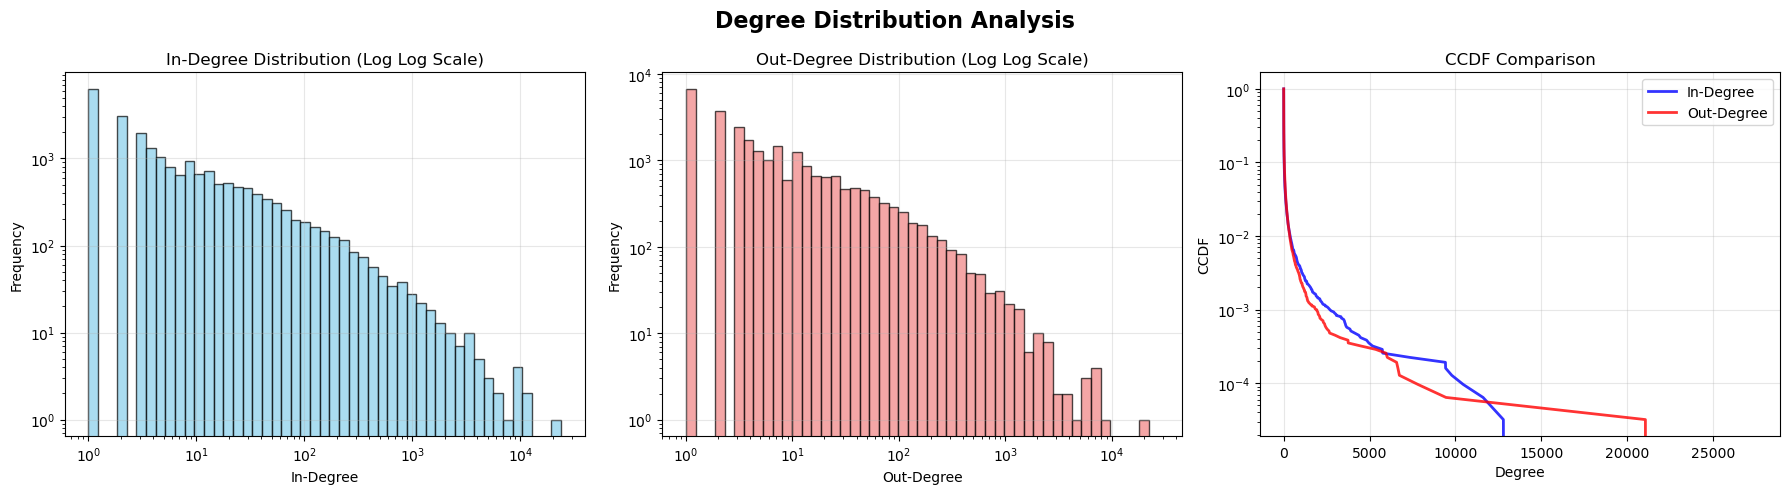

In [2]:
from src.analysis.init_analysis.init_analysis import plot_degree_distribution
plot_degree_distribution(G, show=True)

We plot the in- and out-degree dirstubiton in Log Log scale. As we can see we have a heavy tail distribution for both of them since most of the subreddits in the dataset contain small number of incoming and outgoing cross-linking posts. The same is visible also from the Complementary Cumulative Distribution Function (CCDF) for in and out-degrees.

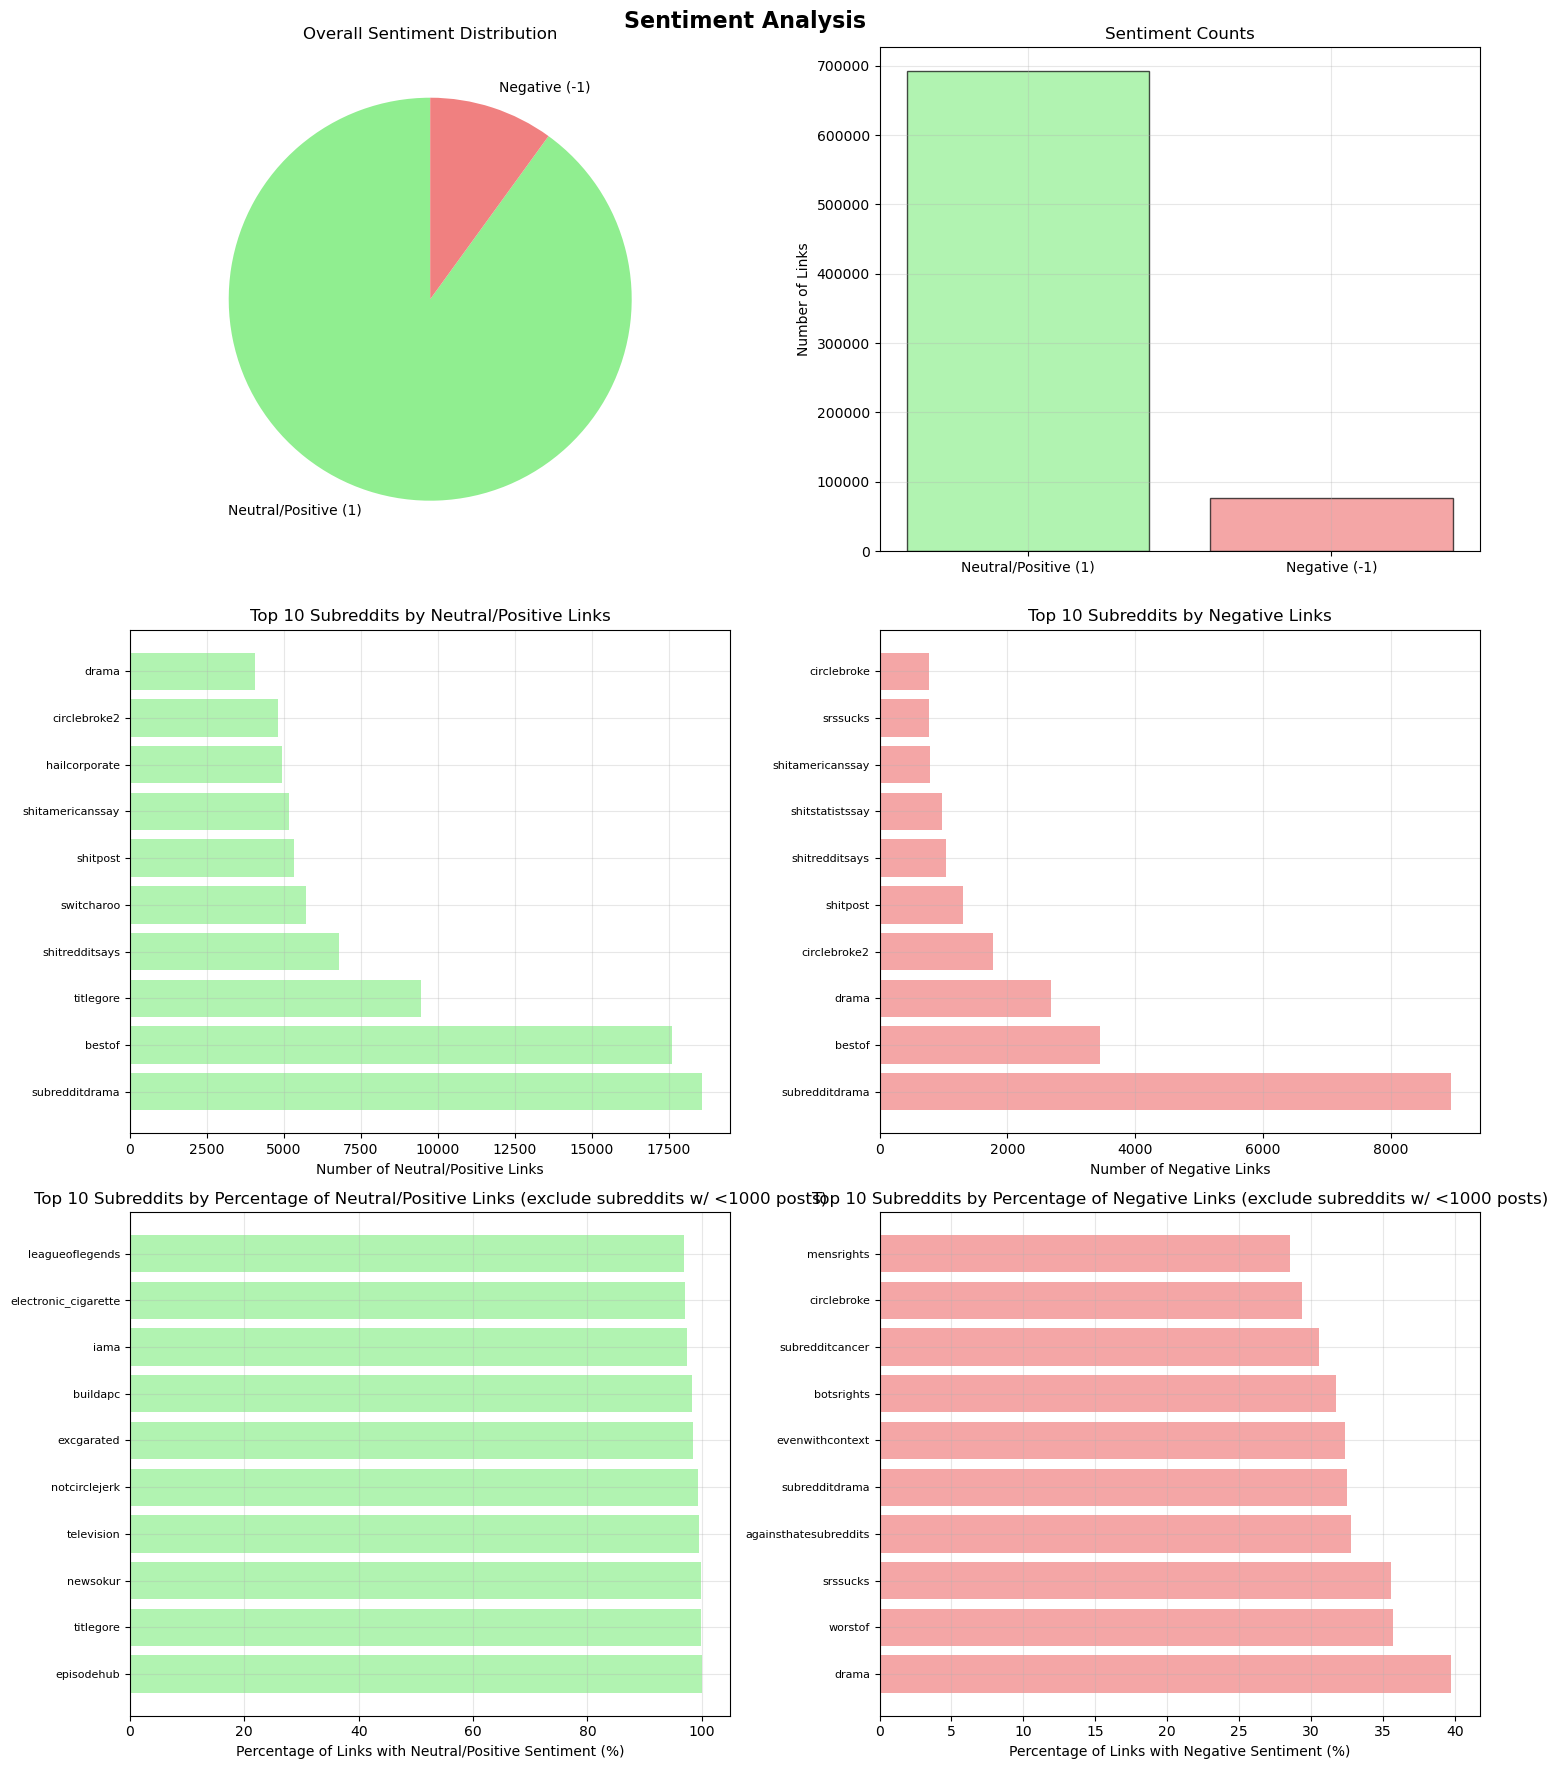

In [3]:
from src.analysis.init_analysis.init_analysis import plot_sentiment_analysis
plot_sentiment_analysis(G, show=True)

We can see that most of the posts in the dataset have Neutral/Positive link sentiment (the sentiment associated with the link in the post). As expected the biggest number of negative cross-links come from subreddits like subredditdrama, drama, shitpost, ssrsucks. What is unexpected is that these subreddits also contain large amounts of Neutral/Positive posts - this can be attributed to the possibility that the authors of the dataset scraped data focusing on negative subreddits or also that those subreddits are simply more active than the other ones in the dataset. On the bottom we plot the most negative and positive subreddits by percentage of posts with a given link sentiment rather than number of posts to account for differently sized subreddits.


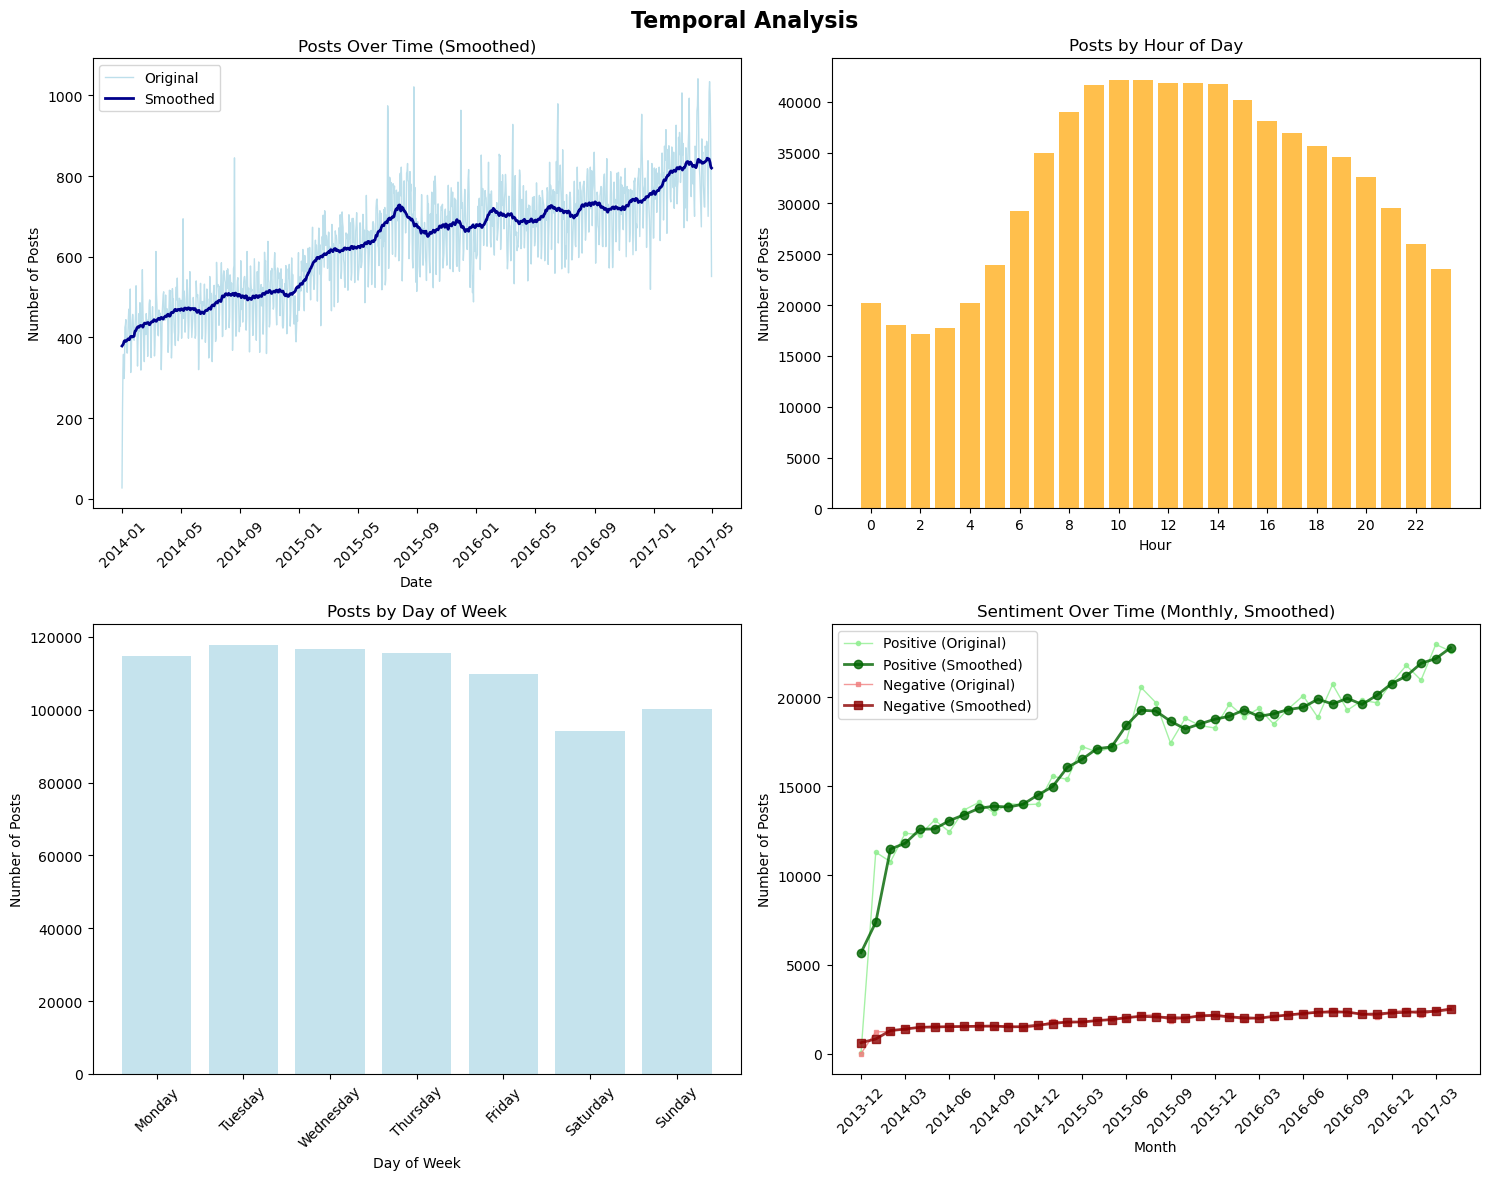

In [4]:
from src.analysis.init_analysis.init_analysis import plot_temporal_analysis
plot_temporal_analysis(G, show=True)

Temporal analysis shows that the number of posts in our dataset generally increases with time (there are also some spikes that are worth looking into). Posts are posted relatively uniformly over days of the week (with a bit of decline over the weekend where less interesting events that people talk about happen) and the distribution seems to be centered around noon UTC. There seems to be an increase in number of positive posts while the number of the negative posts seem to remain the same (but again this might be attributed to the way the authors of the dataset collected the data).

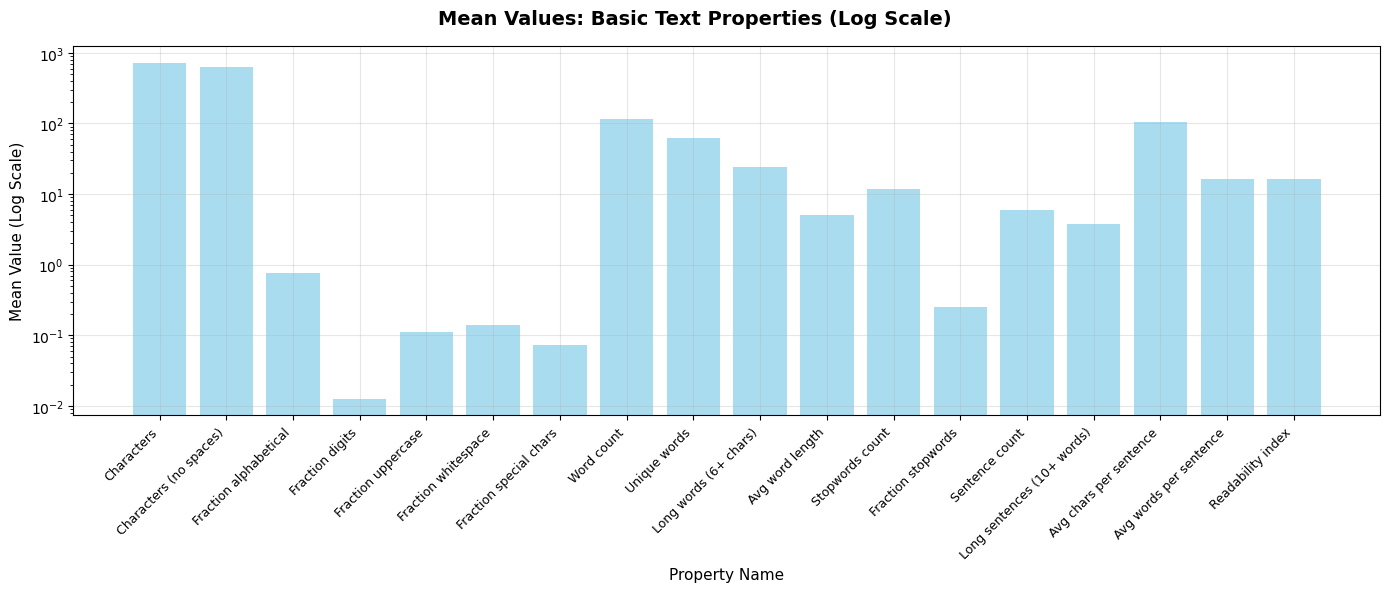

In [5]:
from src.analysis.init_analysis.init_analysis import plot_basic_text_properties

plot_basic_text_properties(G, show=True)

Reddit cross-linking posts are typically long, with character counts (with and without spaces) near 1000. Mean for digits, uppercase, and special characters is low, indicating that cross-linking posts mostly use alphabetical text with few numbers, capital letters, or special symbols.

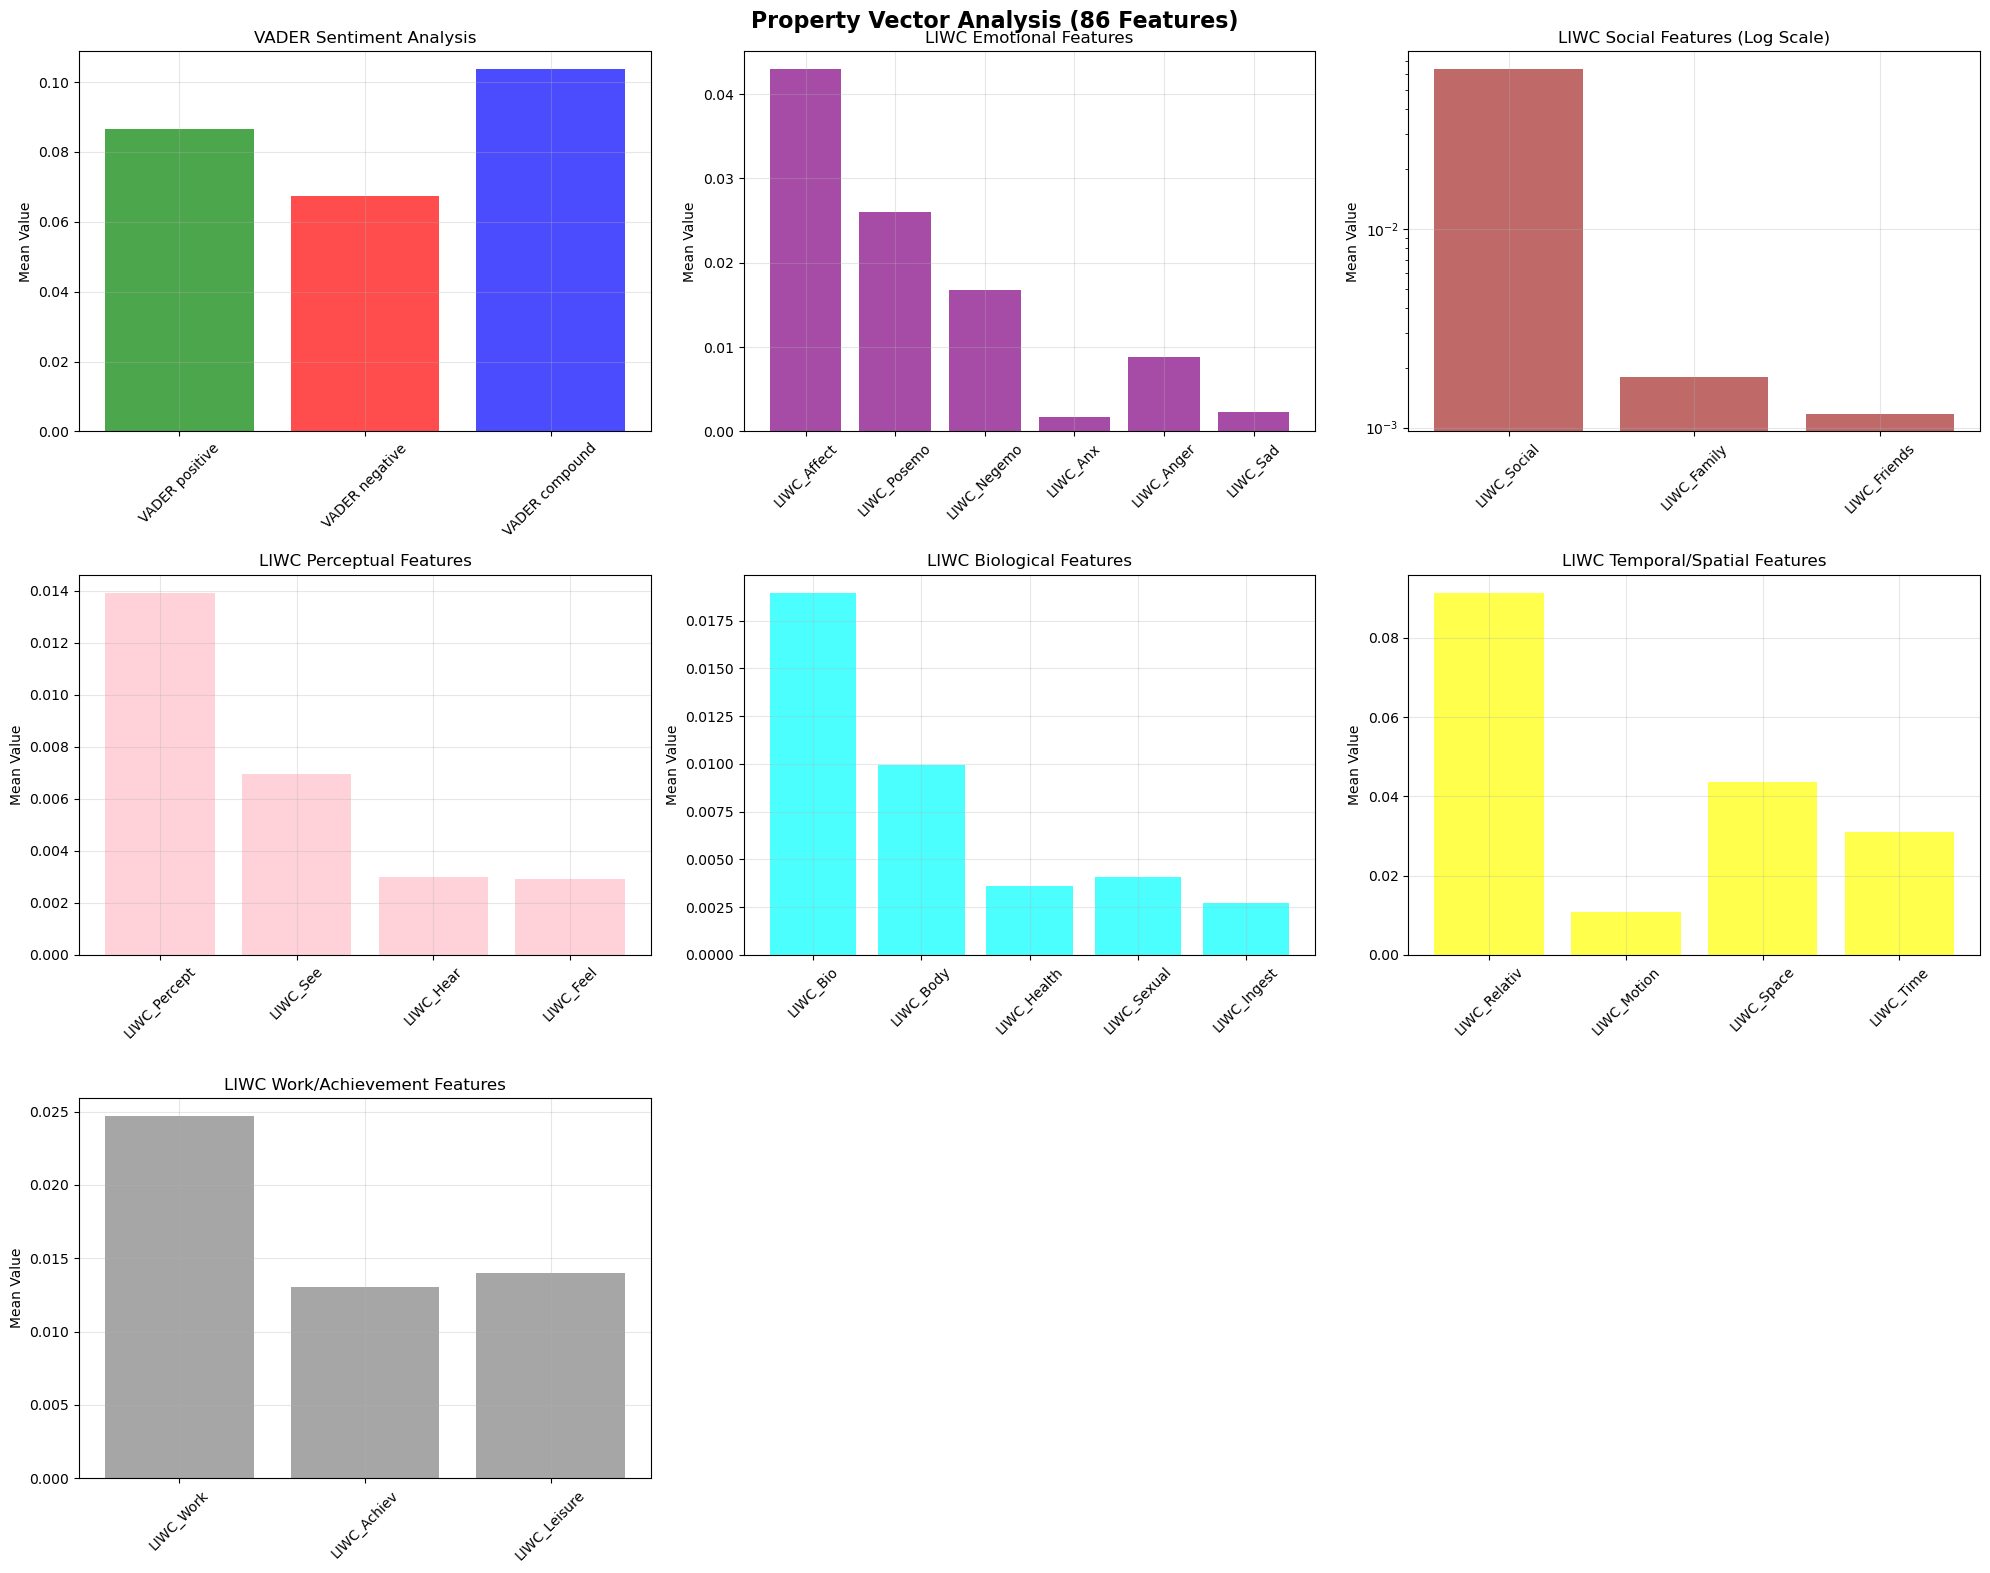

In [6]:
from src.analysis.init_analysis.init_analysis import plot_property_vector_analysis
plot_property_vector_analysis(G, show=True)

Sentiment shows a slight positive VADER bias. Positive emotions (`LIWC_Posemo`) exceed negative (`LIWC_Negemo`), and `LIWC_Affect` has the highest mean among emotional features. Social, perceptual, and biological features show general social language (`LIWC_Social`) and visual perception (`LIWC_See`) dominating over specific references, while general biological (`LIWC_Bio`) and body-related terms are most frequent. Temporal/spatial features show relative terms (`LIWC_Relativ`) to be the most common, and work-related language (`LIWC_Work`) exceeds achievement and leisure features.

The following chart plots the percentage of zero values per feature in the dataset.

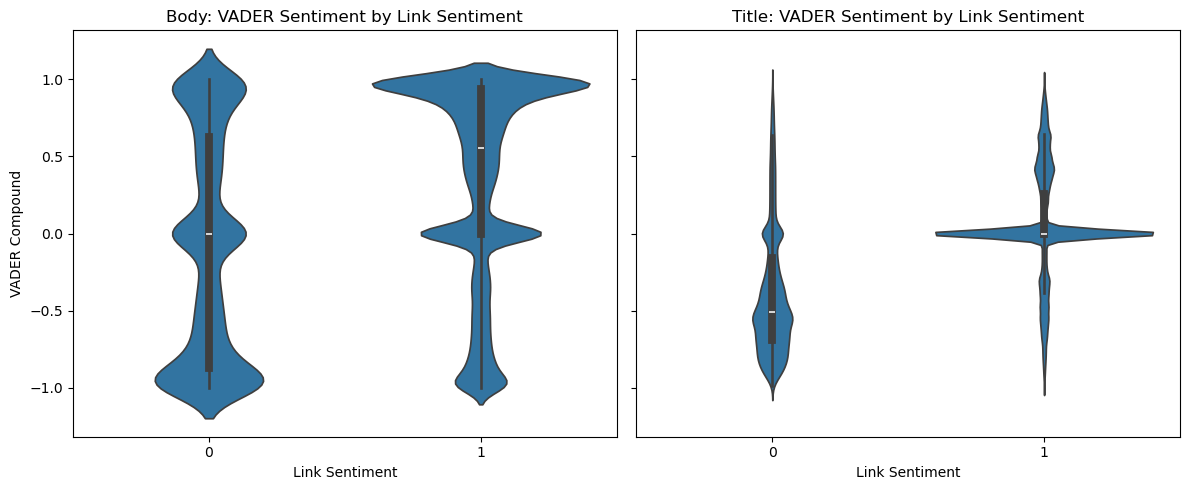

In [9]:
from src.analysis.sentiment_analysis.violin_graphs import draw_violin_plots

draw_violin_plots()

The graph above showcases the correlation between the VADER sentiment and the link sentiments. The left plot shows this for the crosslinking posts in the body while the right one for the title. We can see that posts with a negative link sentiment does not necessarily have a negative overall sentiment, suggesting that the posts are not generally hating but just providing a negative example with the link. For the titular posts, many posts have neutral sentiment, which makes sense because titles are typically shorter and therefore cannot contain too much of a sentiment.

## Enhancing dataset with Reddit API

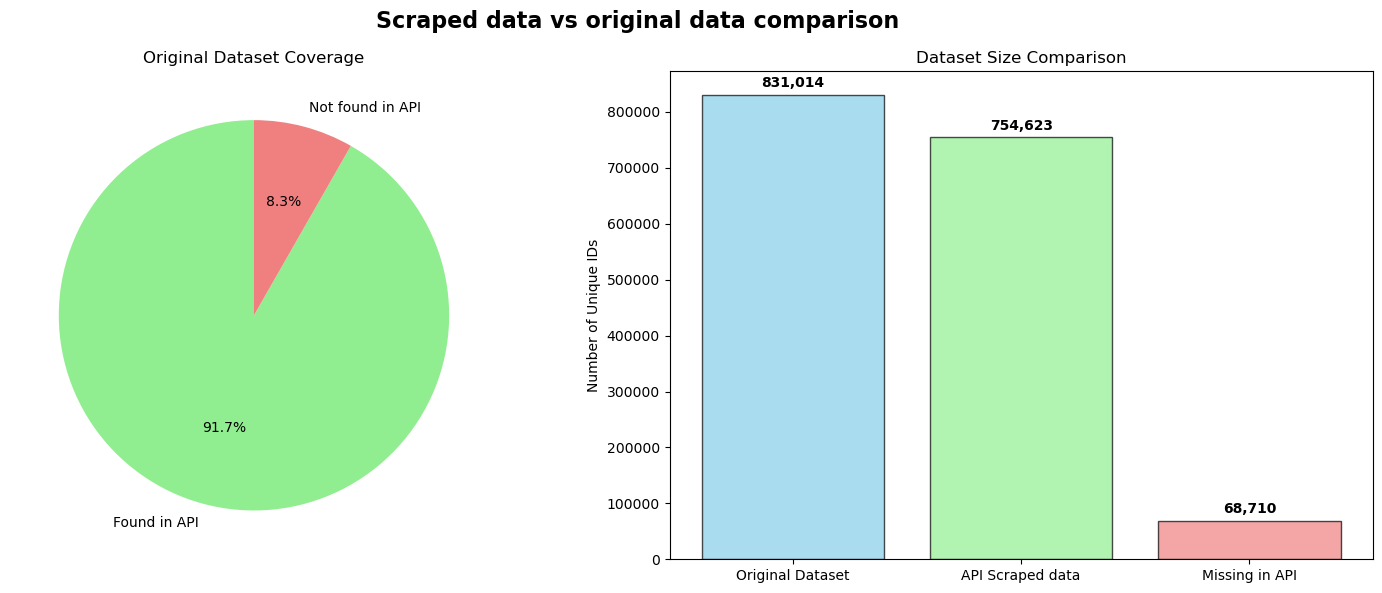

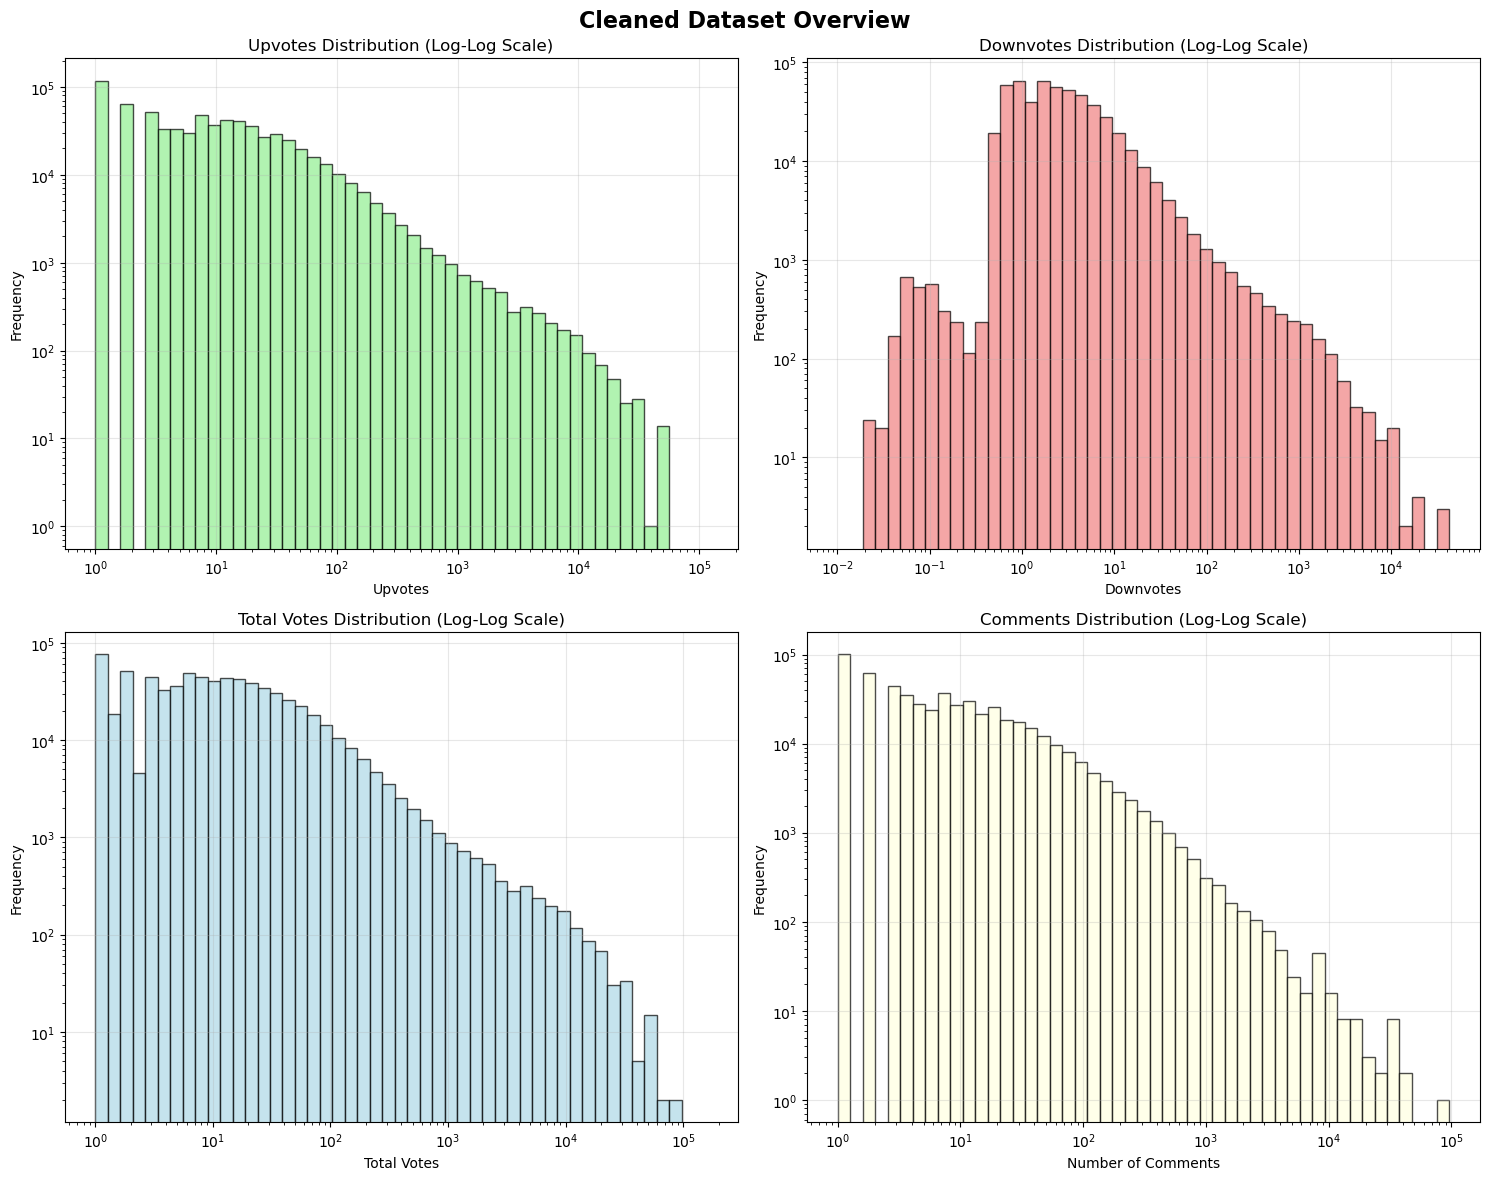

In [10]:
from src.analysis.init_analysis_enhanced.init_analysis_enhanced import create_all_enhanced_analysis_plots

_ = create_all_enhanced_analysis_plots(show=True)

These plots compare the original Stanford SNAP dataset with newly scraped Reddit data, revealing only 8.3% (68,710 posts) overlap between the original 831,014 posts and the 754,623 scraped posts, likely due to deleted content or API limitations. The engagement metrics (upvotes, downvotes, total votes, comments) display heavy-tailed log-log distributions typical of social media, where most posts receive minimal engagement while few achieve viral status.

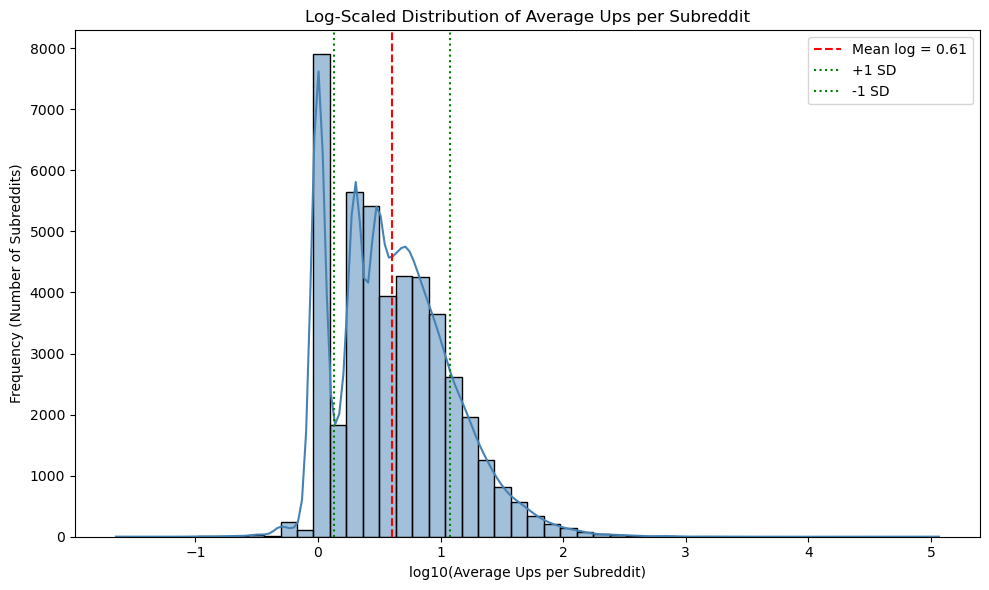

In [11]:
from src.analysis.upvote_analysis.upvote_analysis import see_average_upvotes

see_average_upvotes()

The above plot shows the log scaled distribution of upvotes for all the crosslinking posts. We can see here that a lot of posts have 0 (or close to 0) upvotes, which makes sense as reddit posts often get swallowed by the algorithm and very little engagement. However, there are also a significant number of posts that has 1,000+ upvotes

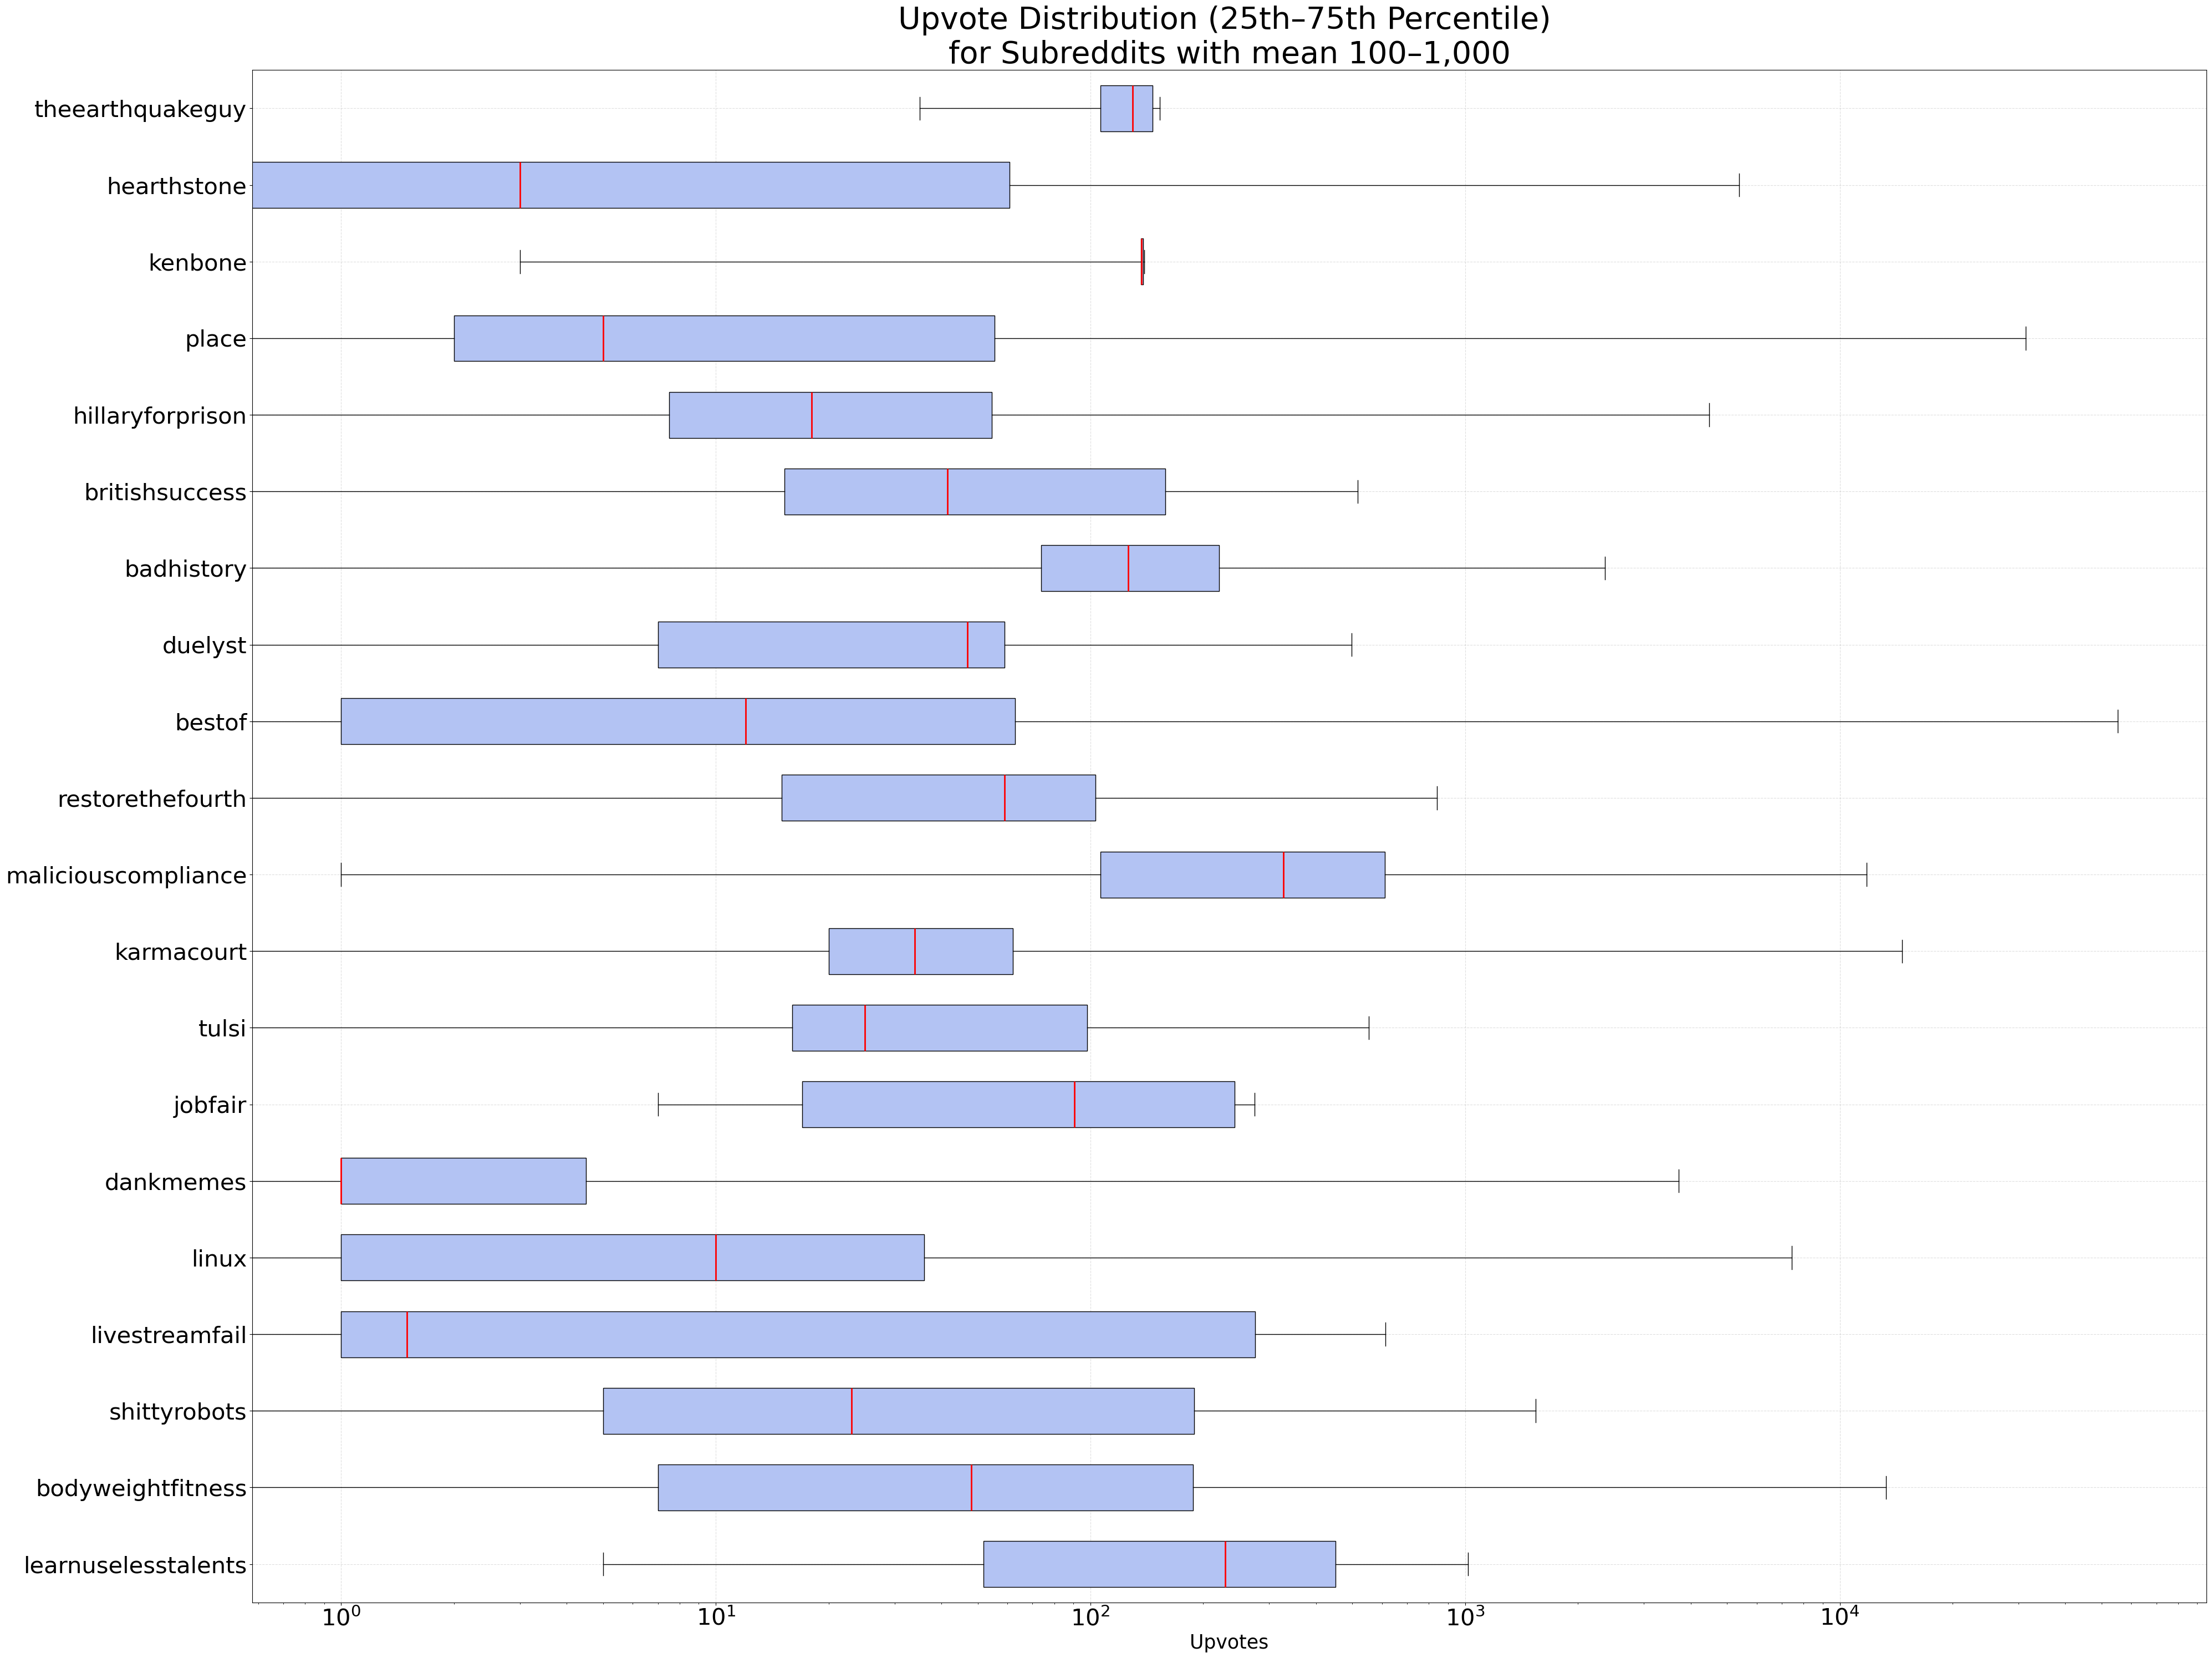

In [12]:
from src.analysis.upvote_analysis.upvote_analysis import upvote_distribution_by_subreddit_one_range

upvote_distribution_by_subreddit_one_range()

This plot shows upvote distribution for select reddits. The reddits were selected to have a similar mean of upvotes, of which a random subset was picked. This analysis shows that distributions of upvotes generally differ a lot, so for our virality analysis we can analyze subreddits with higher propensity of having a post going viral. 

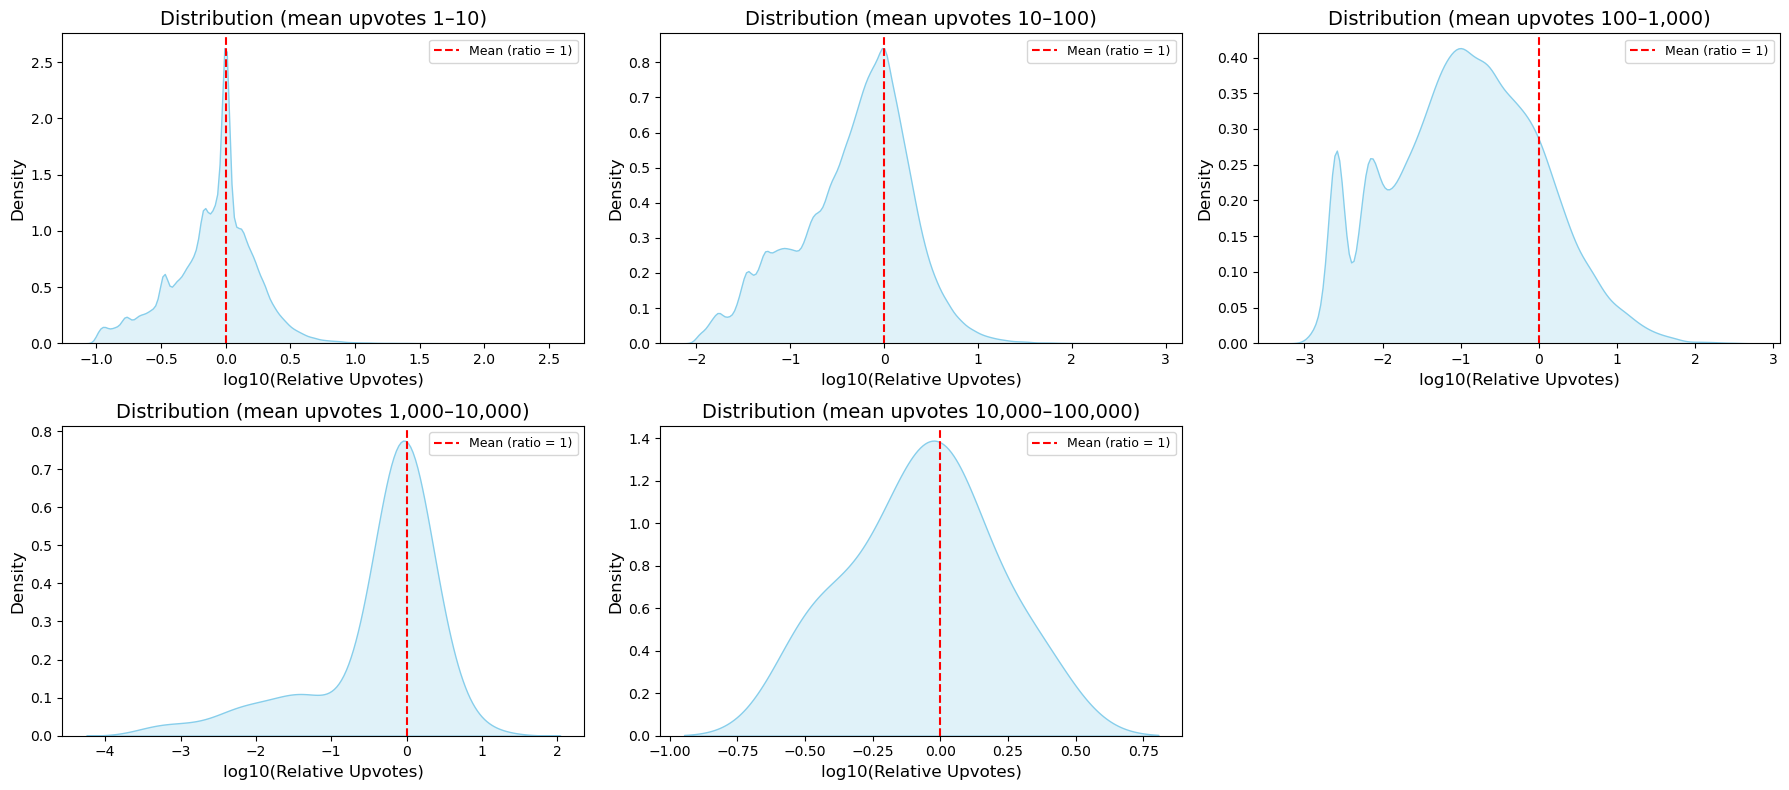

In [13]:
from src.analysis.upvote_analysis.upvote_analysis import upvote_distribution

upvote_distribution()

This plot aggregates subreddits into multiple groups with similar mean upvotes. Then for each of these groups a distribution graph is drawn, using the data of singular posts. The distributions shows that as the mean of the upvotes increases, their variance also increases (even though this plot is drawn logarithmically). This suggests that posts in more popular subreddits are more volatile and require precise crafting in order to achieve vial success.

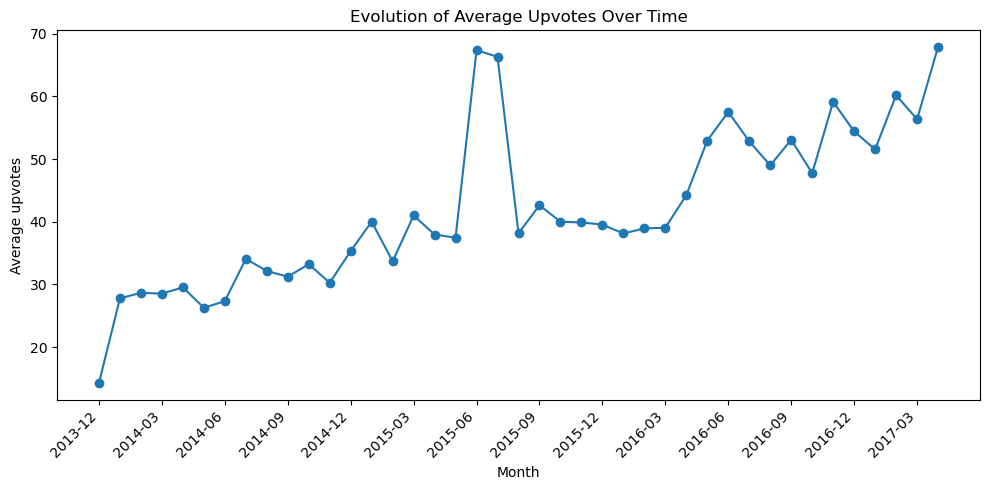

In [14]:
import importlib
import src.analysis.temporal_analysis.temporal_analysis as ta
importlib.reload(ta)
df=ta.load_and_prepare_upvotes()
ta.plot_monthlymean_upvotes(df)

The plot shows the evolution of the average number of upvotes per month over time. Overall, the trend is upward, indicating that Reddit posts in the dataset have been receiving more upvotes on average as time progresses. A noticeable spike around mid-2015 suggests a period of unusually high engagement or viral activity, followed by fluctuations and a steady increase afterward.

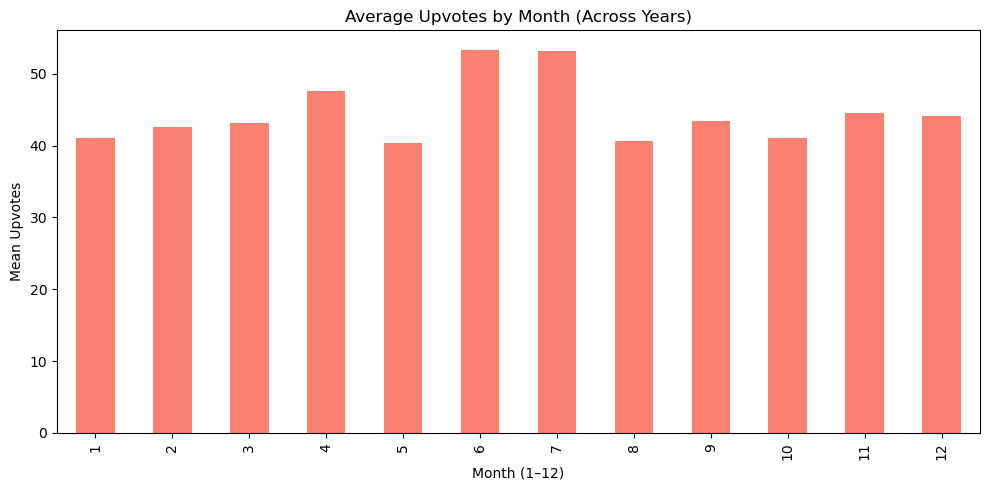

In [15]:
ta.plot_monthly_upvotes(df)

The chart shows the average number of upvotes by calendar month across all years. Upvotes remain fairly stable throughout the year, with a noticeable peak around mid-year (June–July), suggesting higher user engagement during that period.

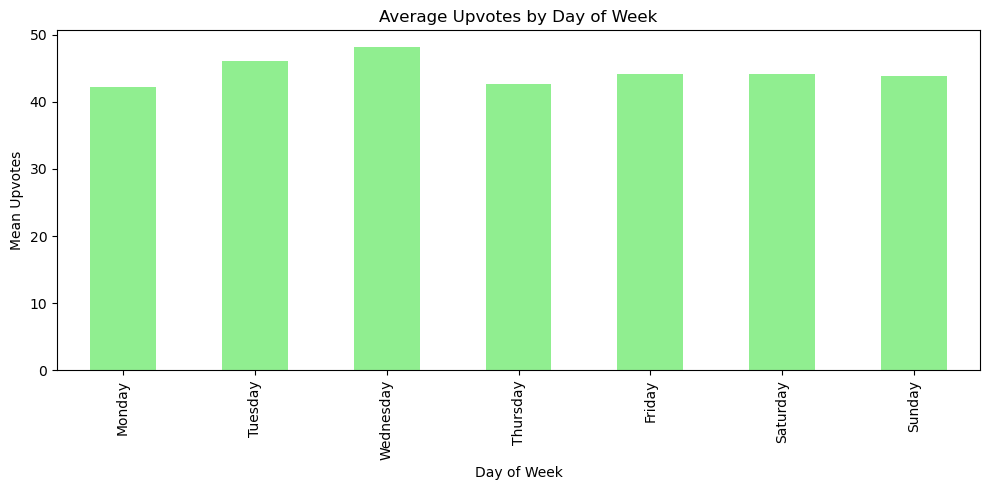

In [16]:
ta.plot_weekday_upvotes(df)

The average number of upvotes is relatively consistent across the week, with a slight increase on Wednesdays and Tuesdays. This suggests that user engagement and post visibility are marginally higher in the middle of the week compared to weekends.

## Enhancing dataset with Embedding dataset

We decided to enrich the subreddit information using [Stanford SNAP Reddit Embeddings](https://snap.stanford.edu/data/web-RedditEmbeddings.html)

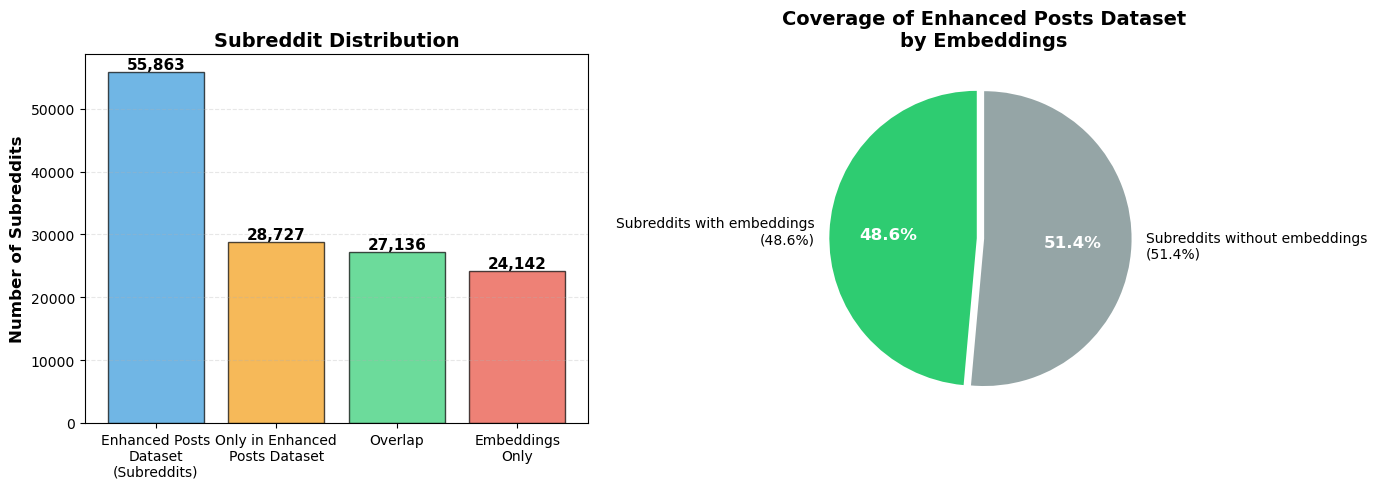

In [17]:
import matplotlib.pyplot as plt
from src.analysis.subreddit_clustering.analyze_overlap import analyze_subreddit_overlap
analyze_subreddit_overlap()
plt.show()

Oh my god, it seems like we have a problem. Only 46% of the subreddits in the enhanced posts dataset have embeddings in the subreddit embeddings dataset. Please scroll down

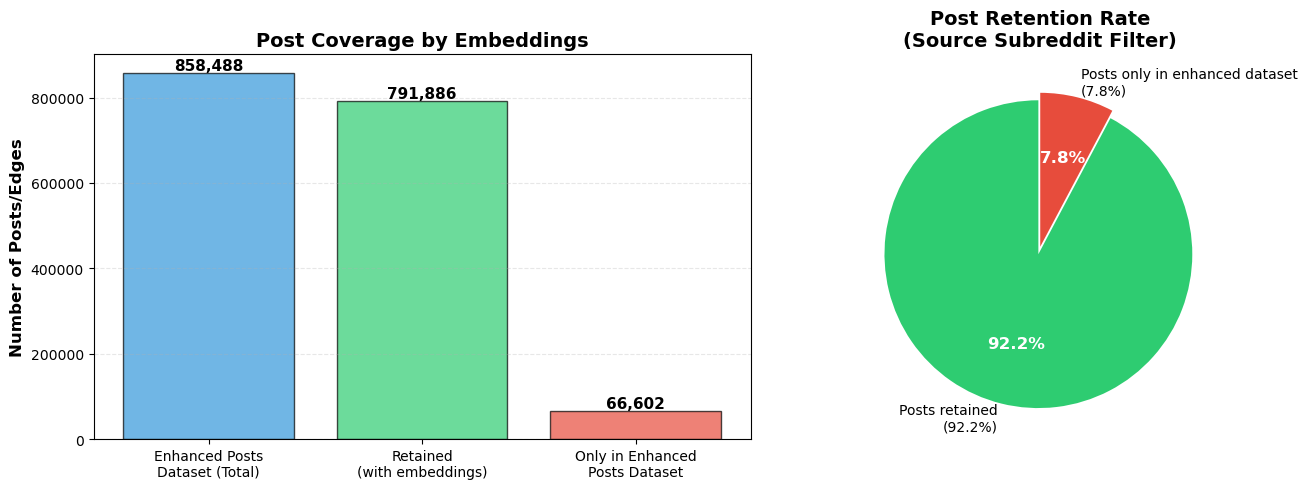

In [18]:
import matplotlib.pyplot as plt
from src.analysis.subreddit_clustering.analyze_overlap import analyze_post_coverage
analyze_post_coverage()
plt.show()

We see here that the issue described just above is not a problem, as the missing subreddits in the embeddings dataset only correspond to 7.8% of the posts in the posts dataset. So we still keep 92.2% of the original post information.

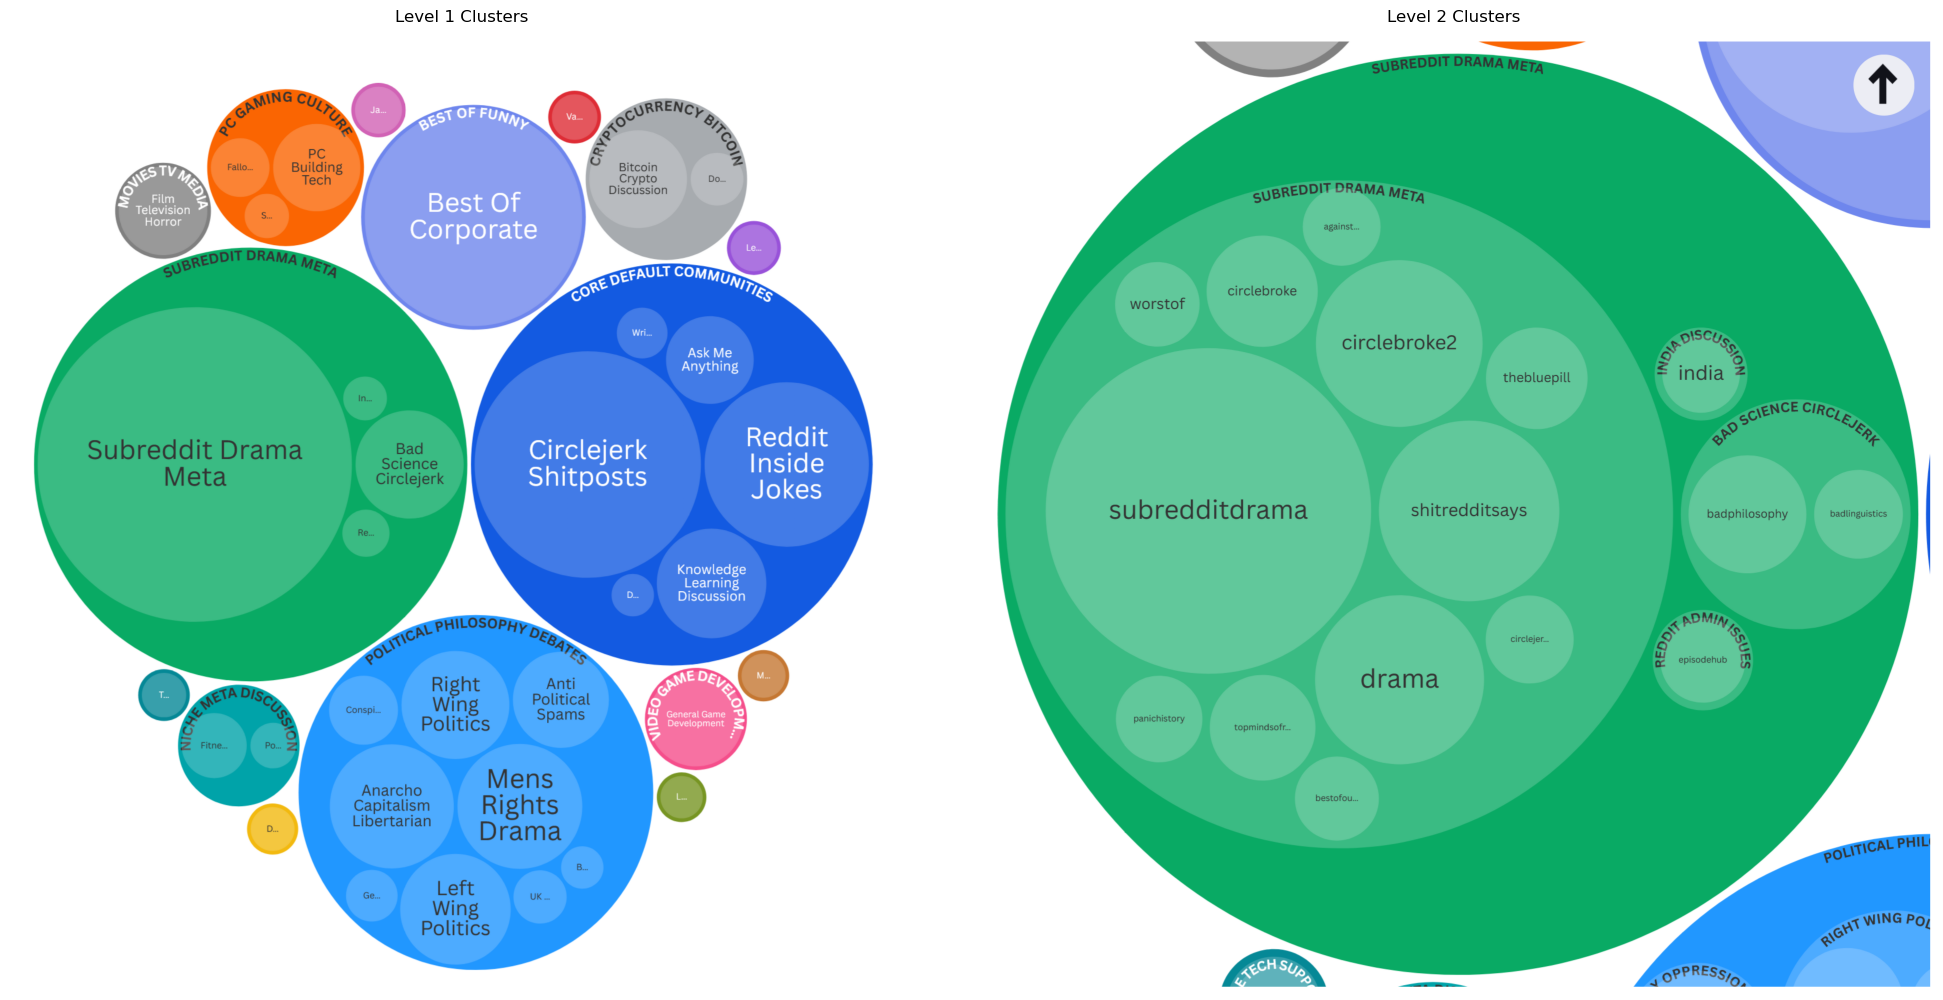

In [19]:
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axarr = plt.subplots(1, 2, figsize=(20, 10))
axarr[0].imshow(mpimg.imread("figures/dynamic_figures/cluster_embeddings_lvl1.png"))
axarr[0].axis('off')
axarr[0].set_title("Level 1 Clusters")

axarr[1].imshow(mpimg.imread("figures/dynamic_figures/cluster_embeddings_lvl2.png"))
axarr[1].axis('off')
axarr[1].set_title("Level 2 Clusters")

plt.tight_layout()
plt.show()

The above plot was generated by using the Leiden algorithm to cluster the embeddings given in the original SNAP dataset. We do hierarchical clustering of all of the embeddings to a maximum depth of 3. We then take the subreddits of each cluster and use multiple instances of Google Gemini to determine appropriate names for each cluster and then use an additional instance to resolve naming discrepancies. We then plot the clusters of subreddits with their names in Flourish. This proves that the subreddit embeddings can be used to meaningfully cluster the subreddits.

After clustering, we perform an initial analysis on the clusters. First, we plot the mean virality of all posts in a top-level cluster:



CLUSTERS RANKED BY VIRALITY_RSS:
Cluster_Technology & Digital Culture: mean=0.0996, median=0.0187, n=50832
Cluster_Sports & Athletics: mean=0.1223, median=0.0556, n=30969
Cluster_Lifestyle & Niche Interests: mean=0.1441, median=0.0414, n=35145
Cluster_Pop Culture & Media: mean=0.1699, median=0.0206, n=99653
Cluster_Gaming & Interactive Entertainment: mean=0.1739, median=0.0454, n=107887
Cluster_Politics & Society: mean=0.2005, median=0.0614, n=123675
Cluster_Reddit Meta & Community: mean=0.2400, median=0.0706, n=235887


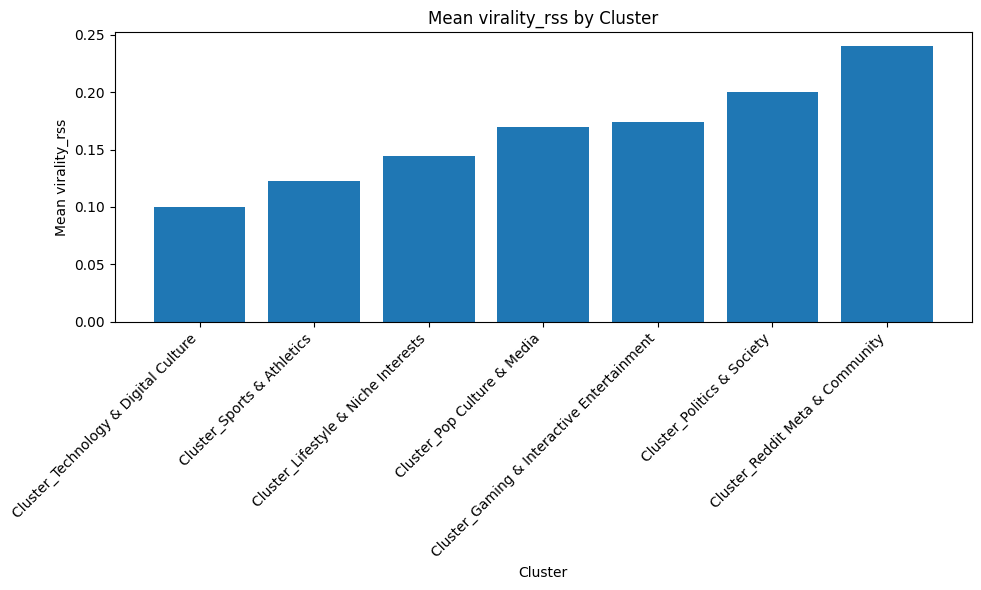


Cluster Statistics:
                                   cluster     mean   median      std      n
      Cluster_Technology & Digital Culture 0.099649 0.018651 0.369105  50832
                Cluster_Sports & Athletics 0.122299 0.055588 0.225027  30969
       Cluster_Lifestyle & Niche Interests 0.144081 0.041367 0.333786  35145
               Cluster_Pop Culture & Media 0.169921 0.020567 0.772470  99653
Cluster_Gaming & Interactive Entertainment 0.173875 0.045443 0.461434 107887
                Cluster_Politics & Society 0.200461 0.061366 0.738757 123675
           Cluster_Reddit Meta & Community 0.240014 0.070590 0.979040 235887


In [39]:
from src.analysis.subreddit_clustering import cluster_pairs_t_test
from src.utils.data_utils import load_final_df
import matplotlib.pyplot as plt
import os

df = load_final_df()

output_dir = 'figures/cluster_analysis'
os.makedirs(output_dir, exist_ok=True)
cluster_col = 'source_supercluster'

# Get cluster names
name_col = cluster_col.replace('cluster', 'cluster_name')
if name_col in df.columns:
    cluster_names = df.groupby(cluster_col)[name_col].first().to_dict()
else:
    cluster_names = {c: f"Cluster_{c}" for c in df[cluster_col].dropna().unique()}


metric = 'virality_rss'             # Define metric to analyze
stats = cluster_pairs_t_test.export_cluster_means(df, cluster_col, cluster_names, metric, output_dir)   # Get stats
means = stats.set_index('cluster')['mean']      # Isolate means


# Plot
plt.figure(figsize=(10, 6))
plt.bar(range(len(means)), means.values)
plt.xticks(range(len(means)), means.index, rotation=45, ha='right')
plt.xlabel('Cluster')
plt.ylabel(f'Mean {metric}')
plt.title(f'Mean {metric} by Cluster')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f'cluster_means_{metric}.png'), dpi=300, bbox_inches='tight')
plt.show()

# Display the statistics table
print("\nCluster Statistics:")
print(stats.to_string(index=False))

Now, we want to do pairwise comparisons between the virality means of each cluster. We use a t-test to obtain the following p-value heatmap:



P-VALUE MATRIX exported to virality_rss_pvalue_matrix.csv


/Users/jane/Library/CloudStorage/OneDrive-epfl.ch/M1/ADA/project/ada-2025-project-standard-deviants-ada/src/analysis/subreddit_clustering/cluster_pairs_t_test.py:131: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_matrix = pvalue_matrix.applymap(lambda x: f'{x:.2e}' if pd.notna(x) else '')


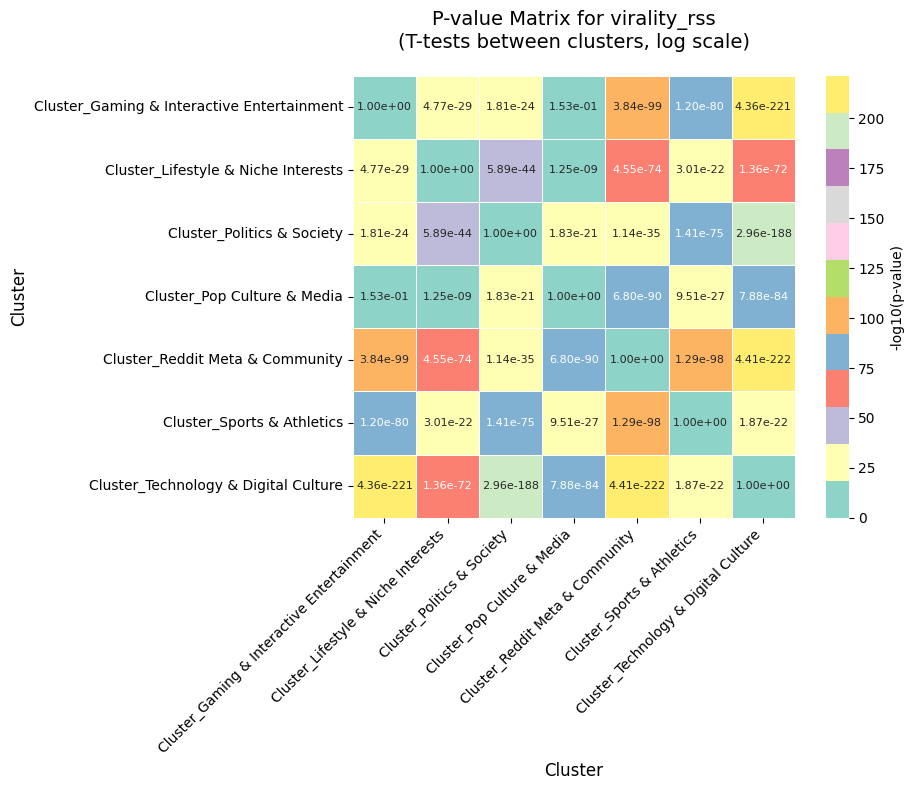

P-VALUE HEATMAP exported to virality_rss_pvalue_heatmap.png


<Figure size 640x480 with 0 Axes>

In [42]:
pvalue_matrix = cluster_pairs_t_test.export_pvalue_matrix(df, cluster_col, cluster_names, metric, output_dir)
cluster_pairs_t_test.plot_pvalue_heatmap(pvalue_matrix, metric, output_dir)

Most p-values outside main diagonal are below 0.05 (one excecption - the pair Gaming & Interactive Entertainment / Pop Culture & Media). Some are much closer to 0 than others, which we convey with a -log scale on the color bar axis. <br>
Since most p-values are below 0.05, we conclude that the differences in `virality_rss` means between our different communities are statistically significant.

## Putting it all together

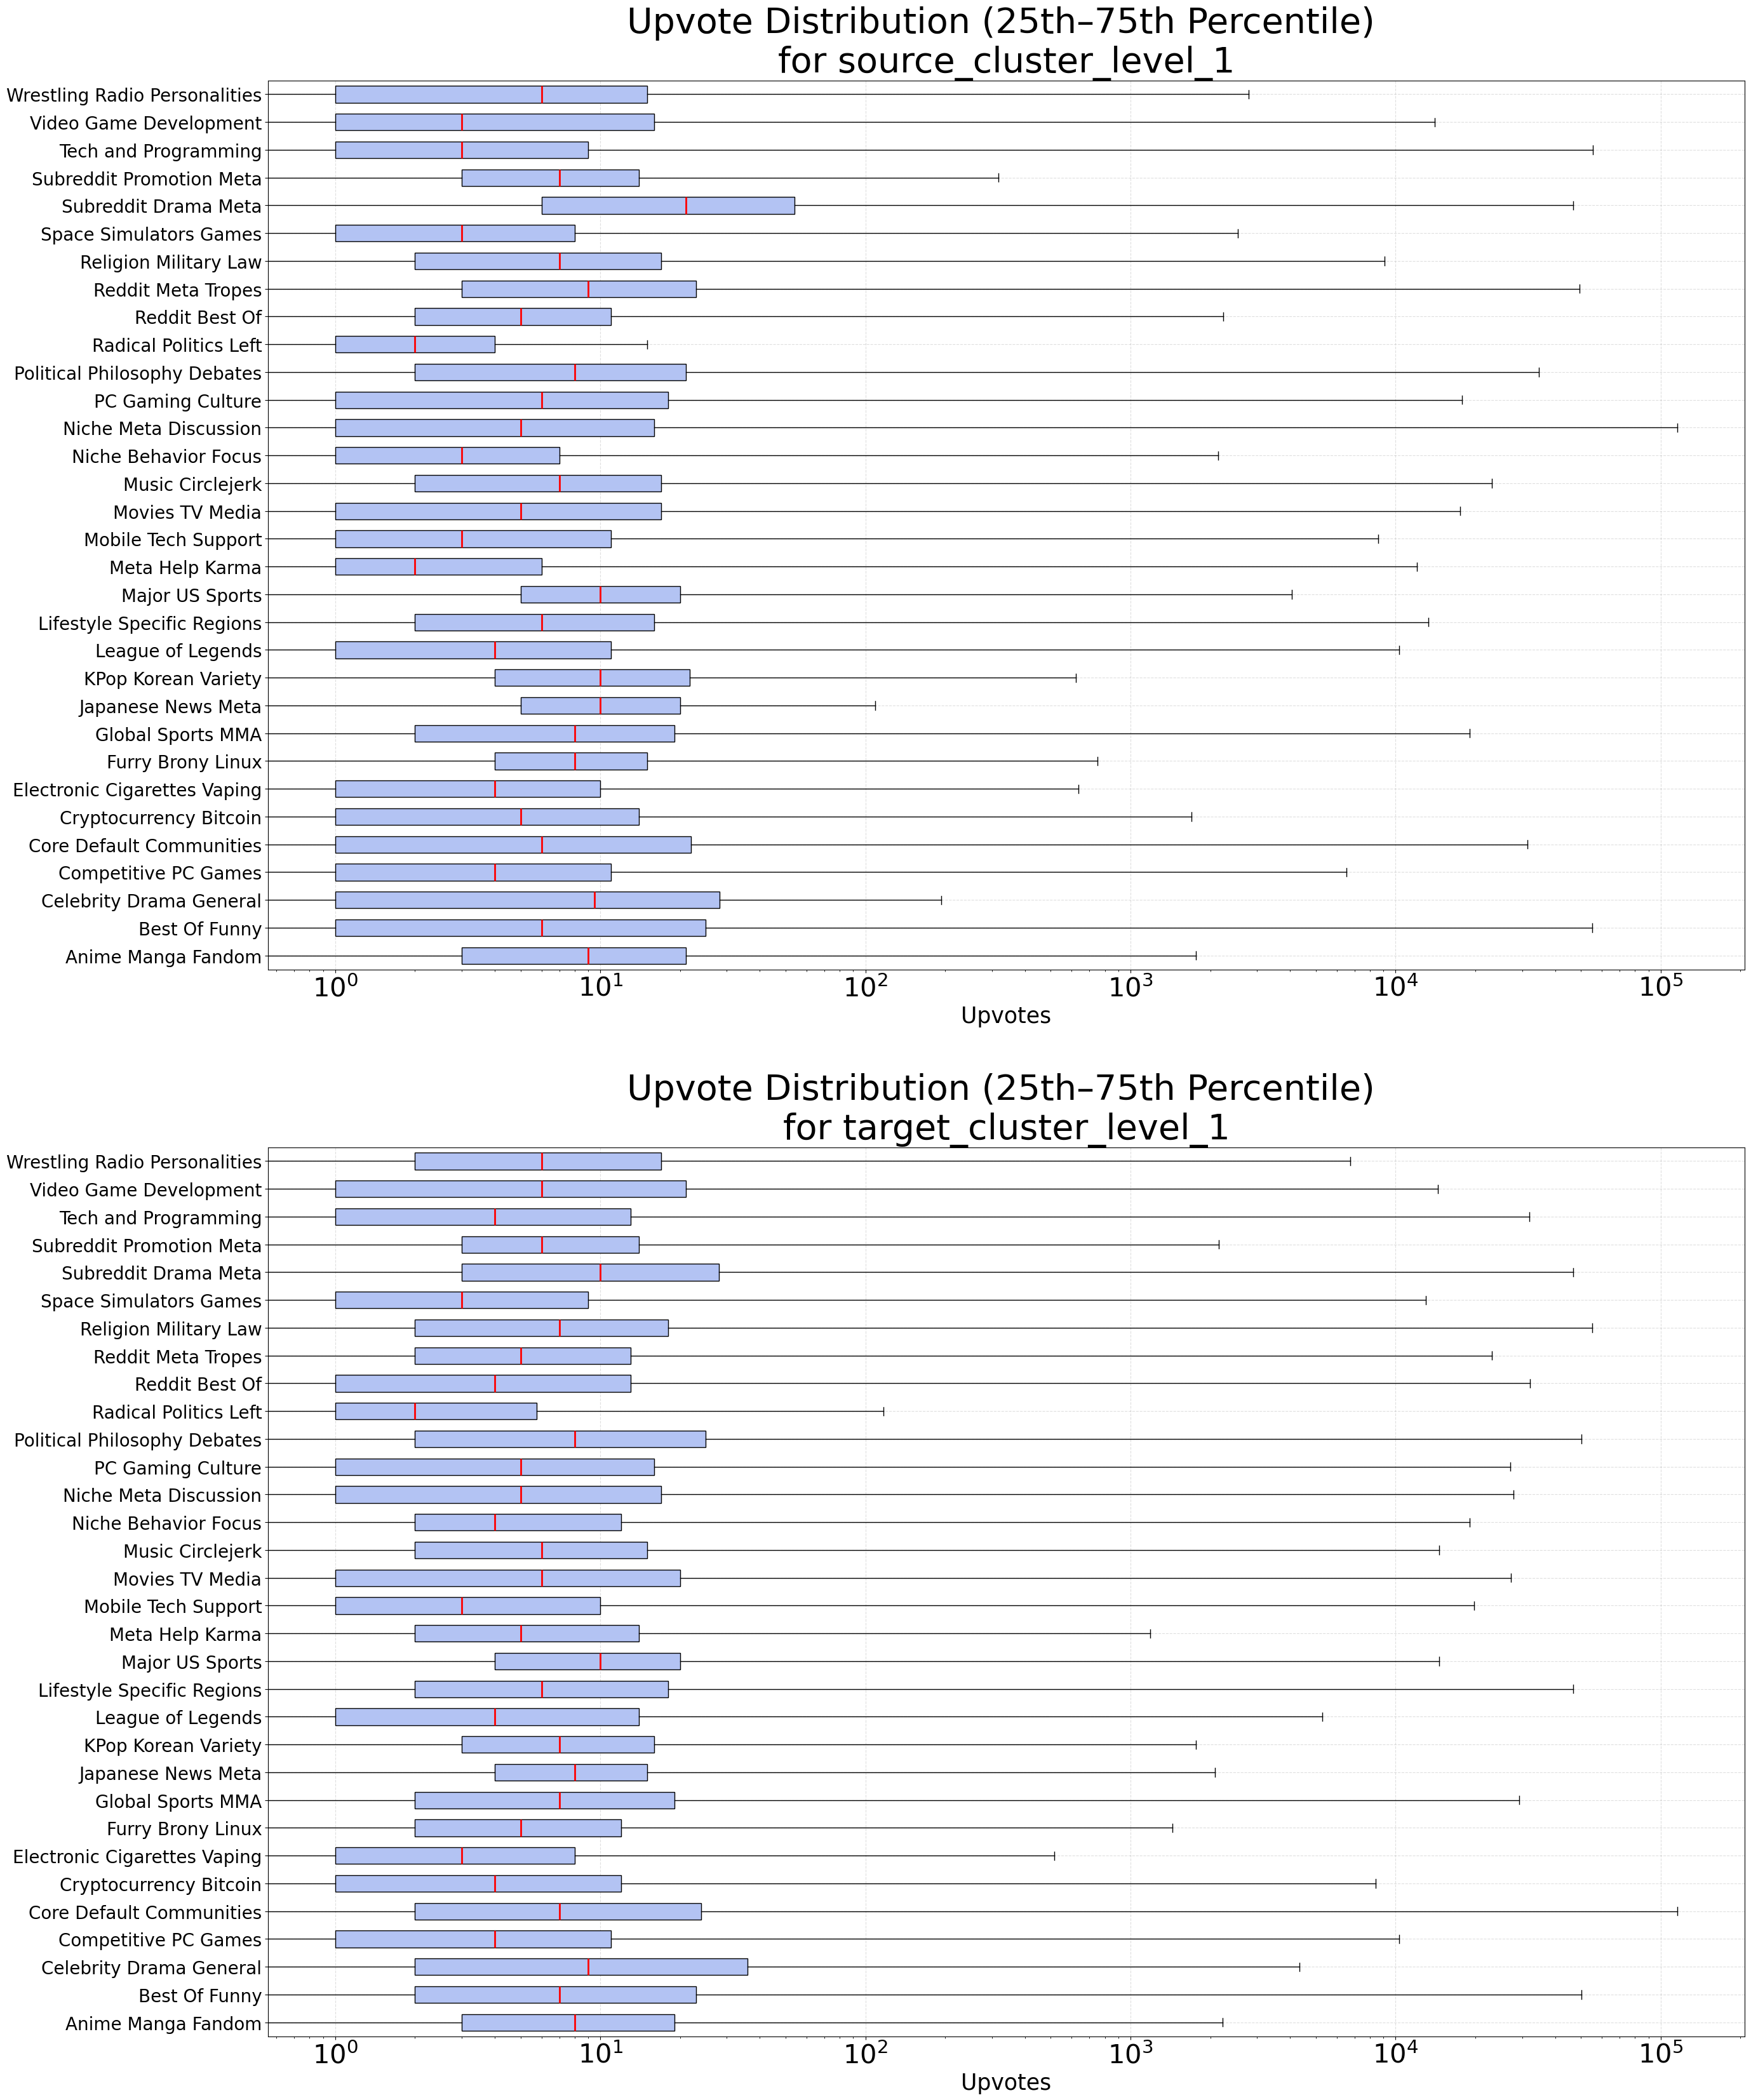

In [20]:
from src.analysis.upvote_analysis.upvote_analysis import cluster_upvote_distribution

cluster_upvote_distribution()

The above two plots show the boxplots for the top level clusters from our analysis. The first plot shows the source cluster the second one the target clusters of crossliking posts. We can see that the distribution of those is rather similar, meaning that for every cluster it is possible to achieve success, one just needs to be careful where and how to post. Choosing the correct subreddit within a cluster and the right sentiment makes a huge difference in change of going viral.

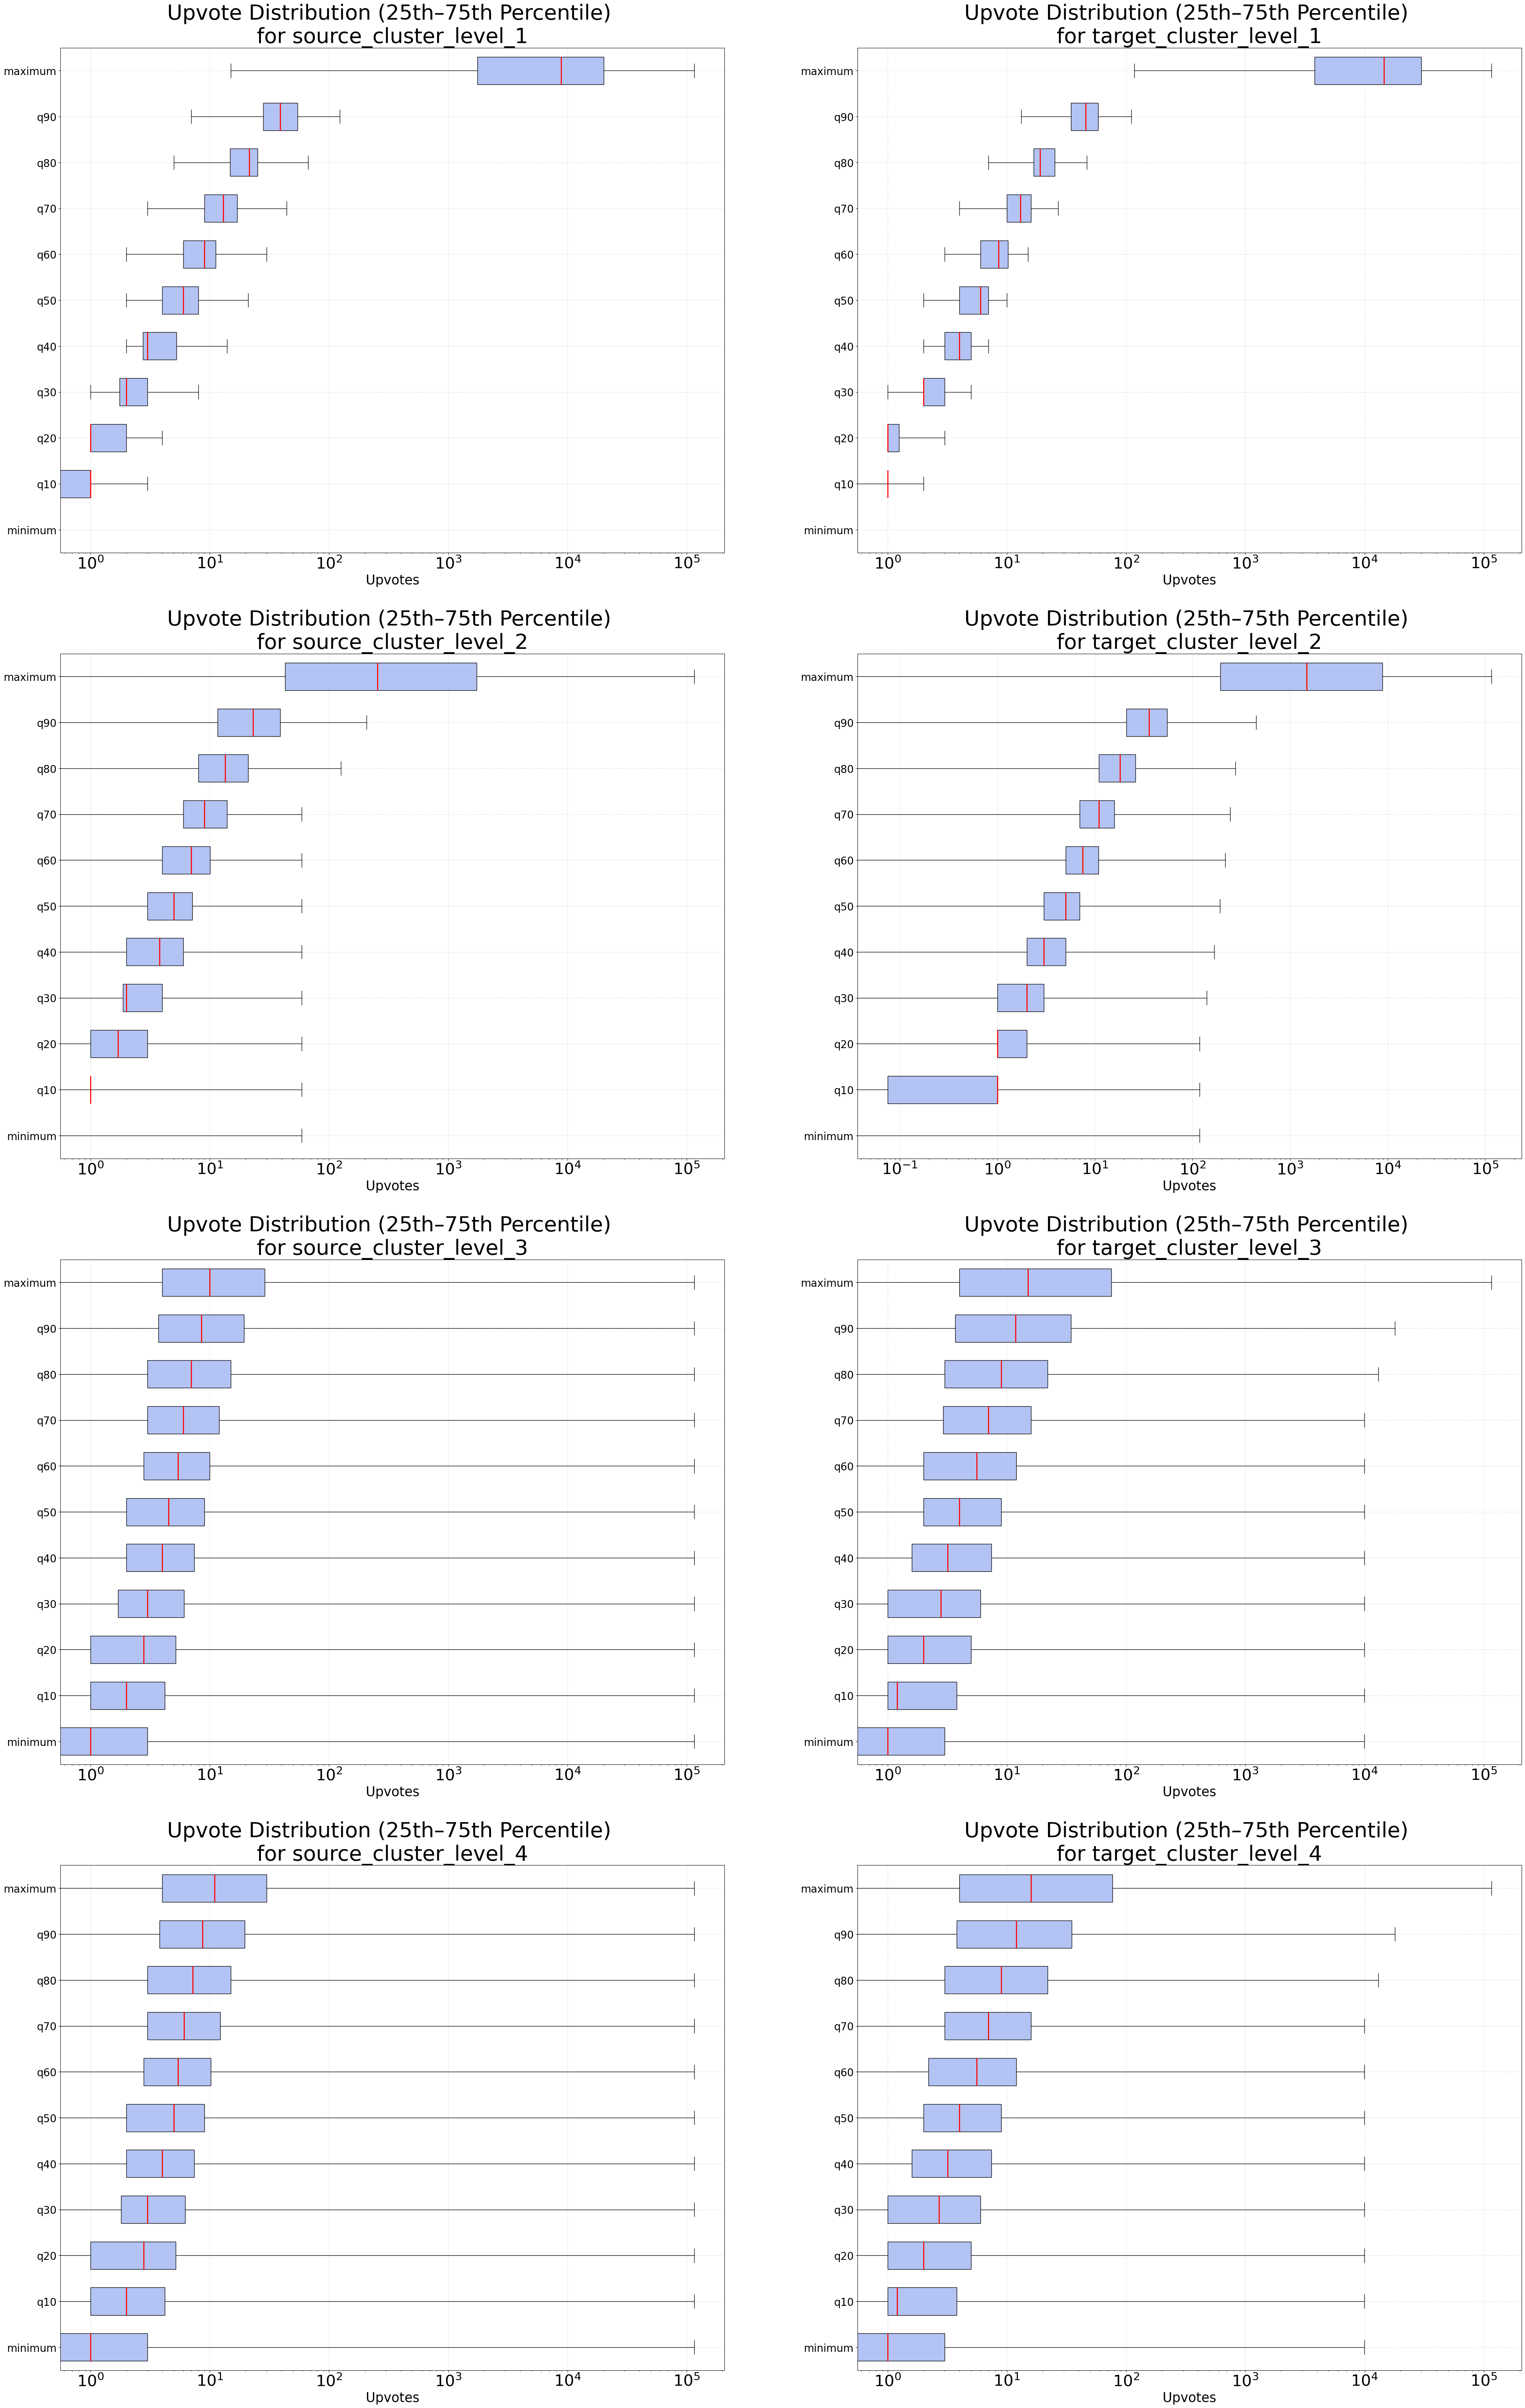

In [21]:
from src.analysis.upvote_analysis.upvote_analysis import cluster_percentiles_distribution

cluster_percentiles_distribution()

The above plots (one level of clustering per row) show how similarly the quantiles in upvotes are distributed across all the different cluseters. We can see that the quantiles (e.g. q10, ..., median, ..., max) on top level clusters (level 1) are fairly close together, meaning that these clusters have quite similar distributions. As the clusters become more fine-grained, the distributions change, meaning choosing the correct fine-grained cluster might be more important than choosing the correct subreddit in the cluster.'

## Defining sentiment in the Reddit network

In order to explore the sentiment relations between pairs of subreddits we have to take our graph `G` that is an `nx.MultiDiGraph` (Directed multigraph - there could be multiple parallel edges/posts between each pair of nodes/subreddits) that contains all of the cross-linking posts (with hundreds of parallel edges between some pairs of subreddits) and aggregates them so that we get `nx.DiGraph` (with only one weighted edge between each pair of subreddits).

We experimented extensively (for the full list of metrics that we have experimented with see `src/analysis/sentiment_graphs/graph_metrics.ipynb` for more info) with different metrics of hate and affection. The best ones (heuristically chosen) we currently have are described below.

**Sentiment intensity**: $w = \frac{n_{neg}}{n_{total}} \cdot \log(1 + n_{neg})$ (or $n_{pos}$ if we are interested in positive sentiment intensity)

Where $n_{neg}$, $n_{pos}$ and $n_{total}$ is the number of negative, positive and total number of cross-links.

**Emotional_toxicity**: $w = \text{mean}\left(\frac{\text{vadernegative} + \text{LIWCnegemo} + \text{LIWCanger} + \text{LIWCanxiety} + \text{LIWCsad} + \text{LIWCswear}}{6}\right)$

**positive_emotion**: $w = \text{mean}\left(\frac{\text{LIWCposemo} + \text{vaderpositive} + \max(\text{vadercompound}, 0)}{3}\right)$

Where the `LIWC*` and `vader_*` are the numerical properties of the post. 

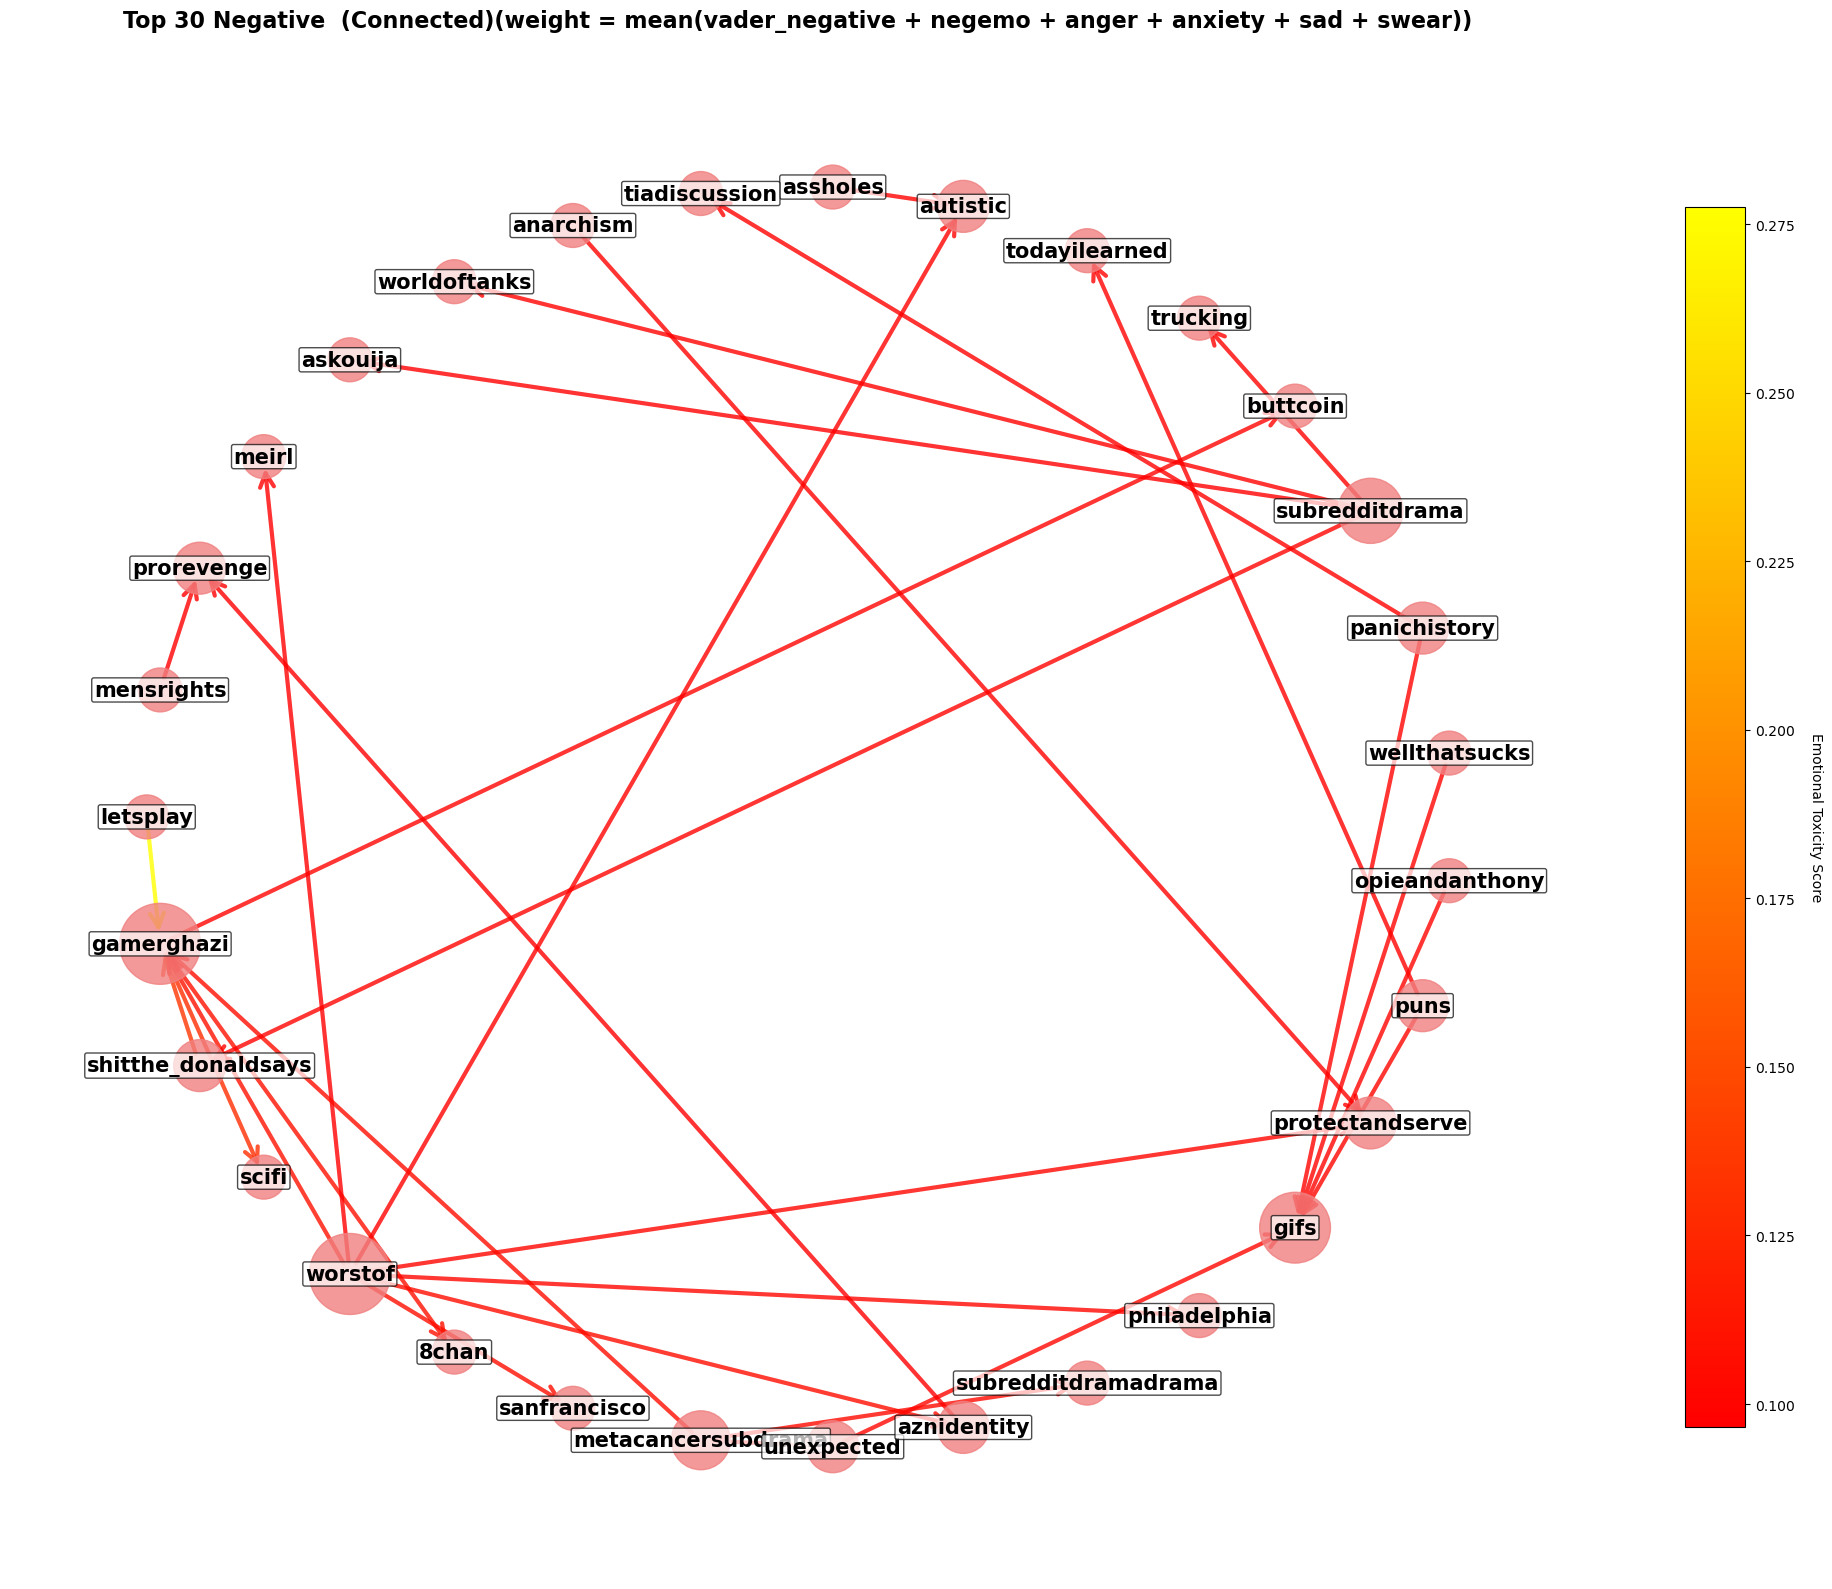

In [7]:
from src.analysis.sentiment_graphs.create_sentiment_graph import create_and_visualize_graph

create_and_visualize_graph(G, 'emotional_toxicity', sentiment='neg', top_n=30, show=True, export_csv=True, connected=True)

## Advanced analysis

Evolution of the top 10 attacking subreddits over time, based on quarterly attack counts.

A similar movement is observed for subreddits with negative sentiment posts, showing notable changes in the top upvoted communities and their average upvotes over time.  
If this figure is not showing up, click [Here](https://public.flourish.studio/visualisation/25923109/)

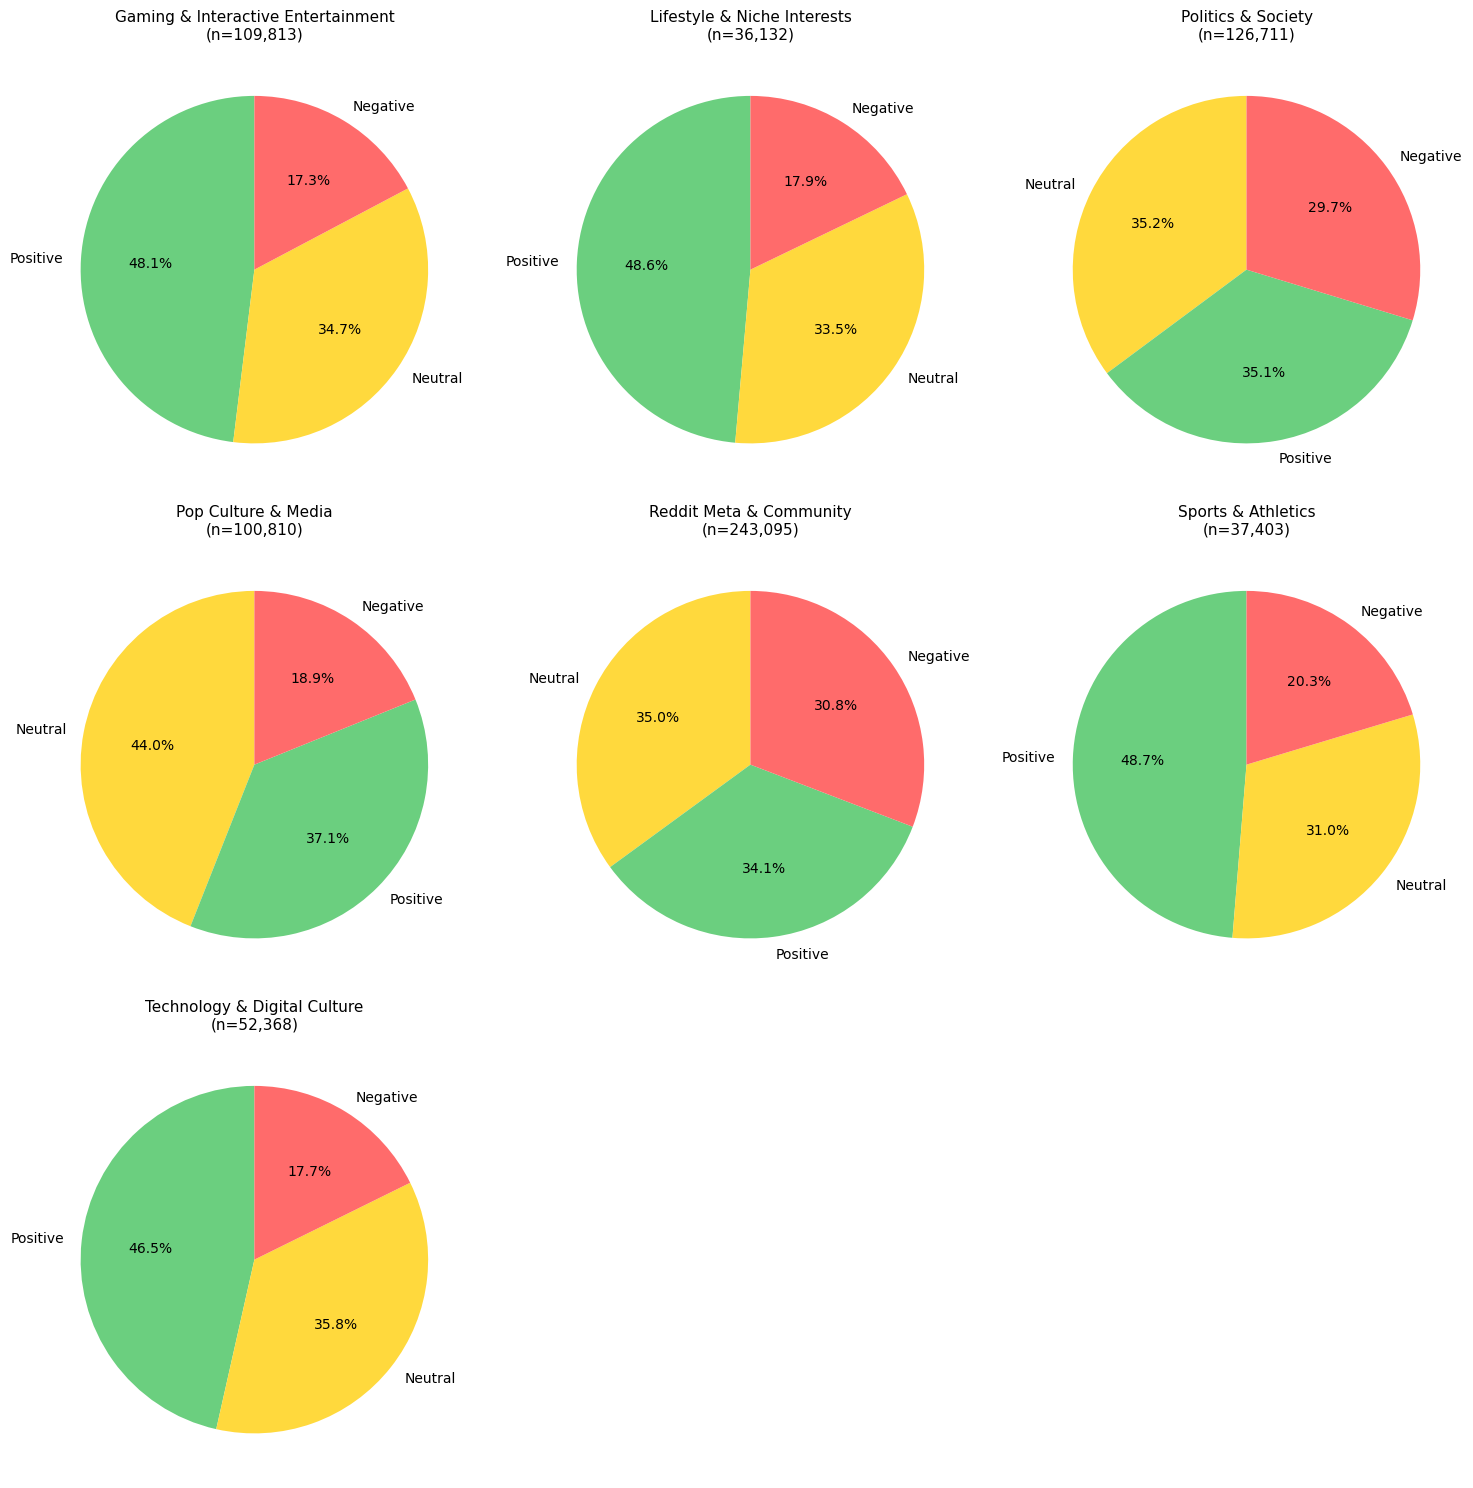

In [1]:
from src.analysis.subreddit_clustering.cluster_sentiment import plot_supercluster_sentiment
plot_supercluster_sentiment(save=False, show=True)

In [5]:
from src.utils.data_utils import load_final_df
from src.analysis.virality_analysis.get_viral_posts import get_viral_posts

df = load_final_df(calculate_rss=True)
df = get_viral_posts(df, virality_percentile=0.98, window_size='60D')

In [62]:
f"Current number of posts: {len(df)}"

'Current number of posts: 684041'

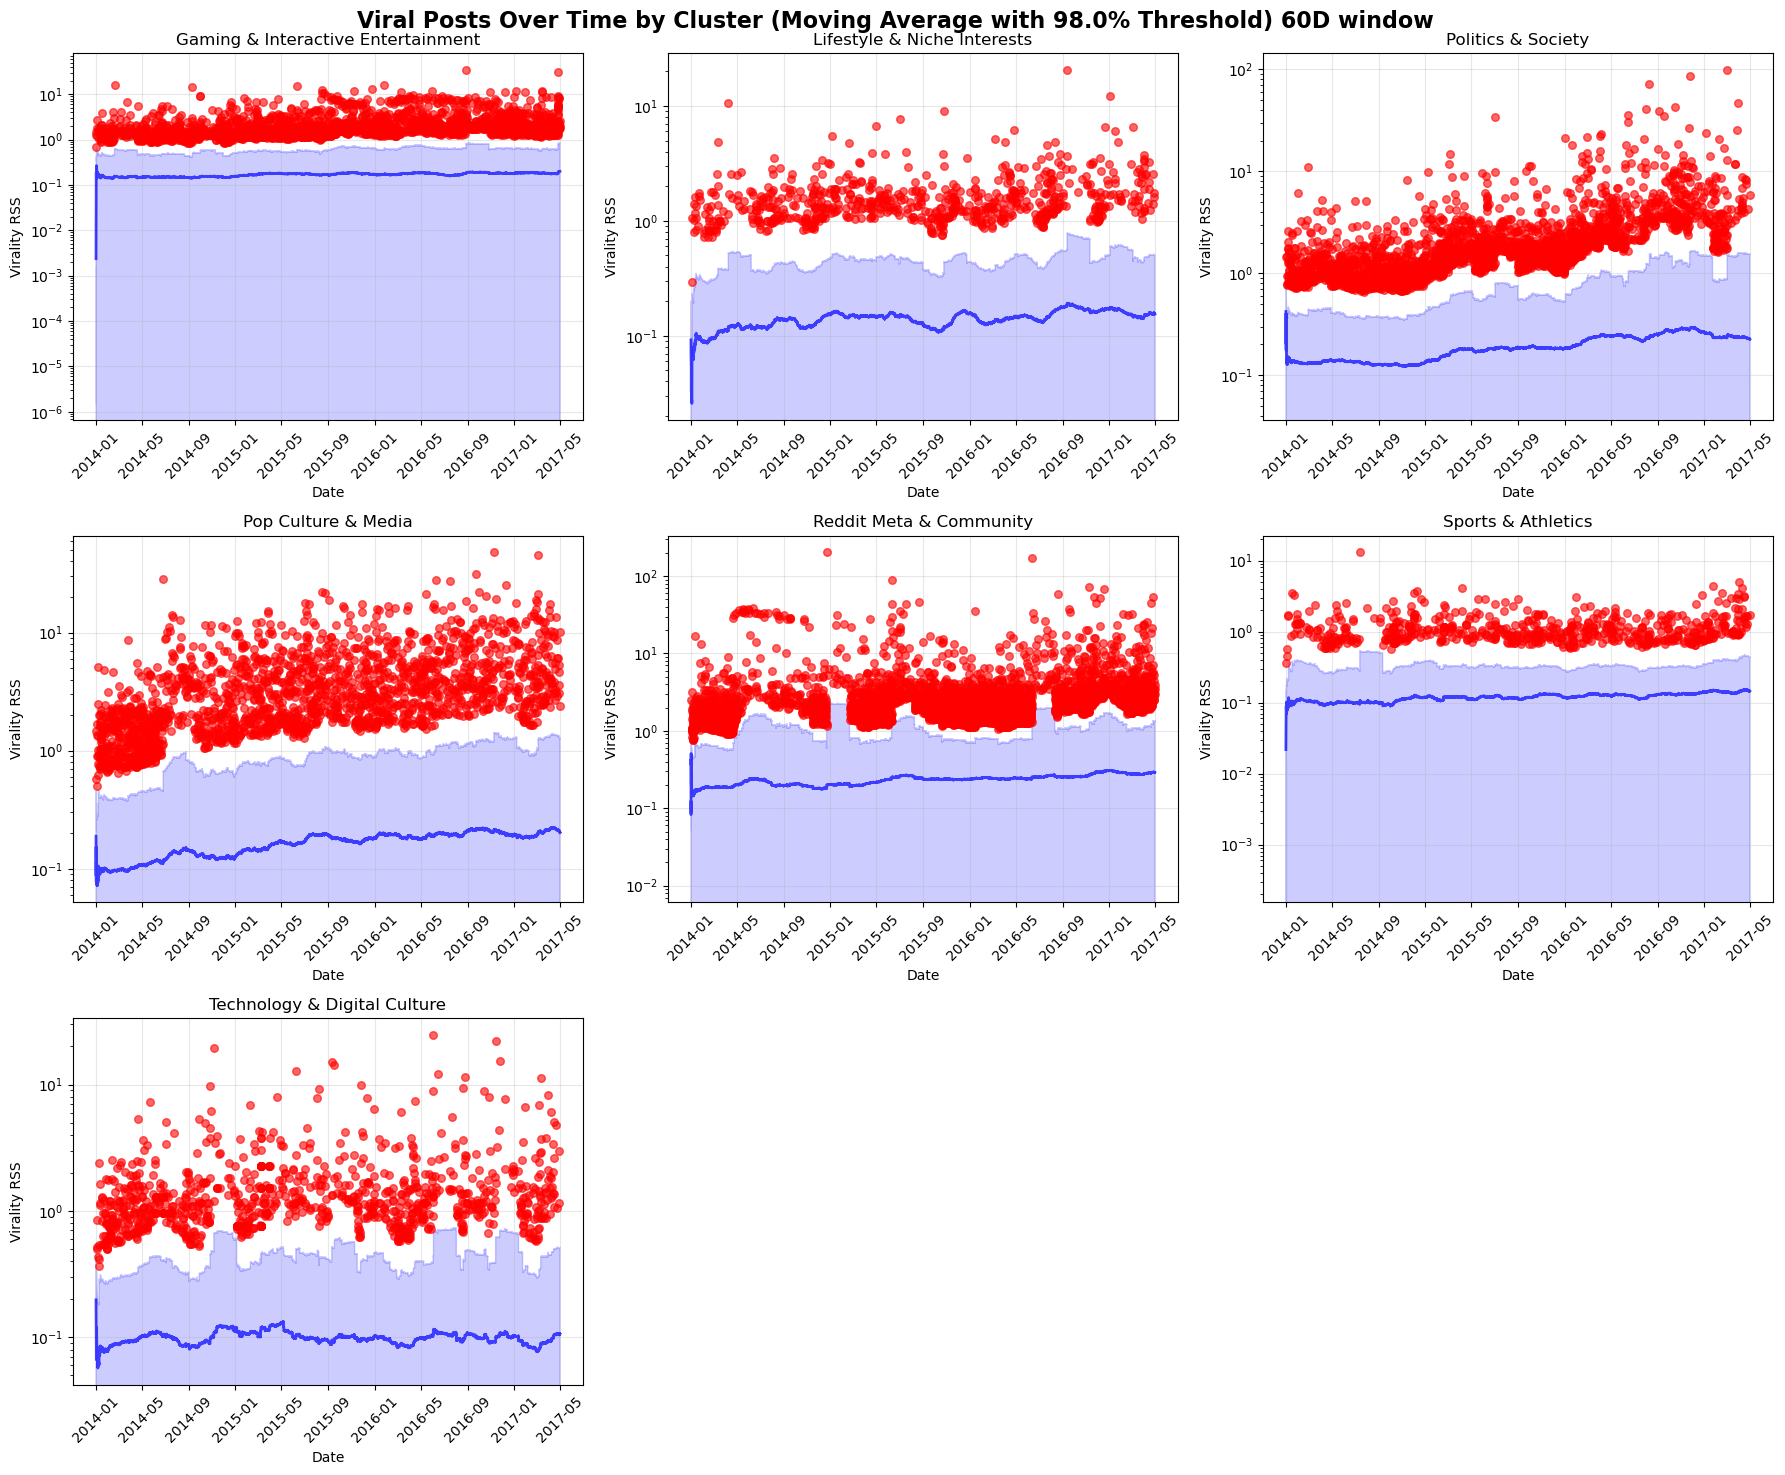

In [39]:
from src.analysis.virality_analysis.get_viral_posts import plot_viral_posts

plot_viral_posts(df, virality_percentile=0.98, window_size='60D', show=True)

In [41]:
import importlib
import src.analysis.virality_analysis.logistic_regression
importlib.reload(src.analysis.virality_analysis.logistic_regression)
from src.analysis.virality_analysis.logistic_regression import logistic_regression

print("Module reloaded!")

Module reloaded!


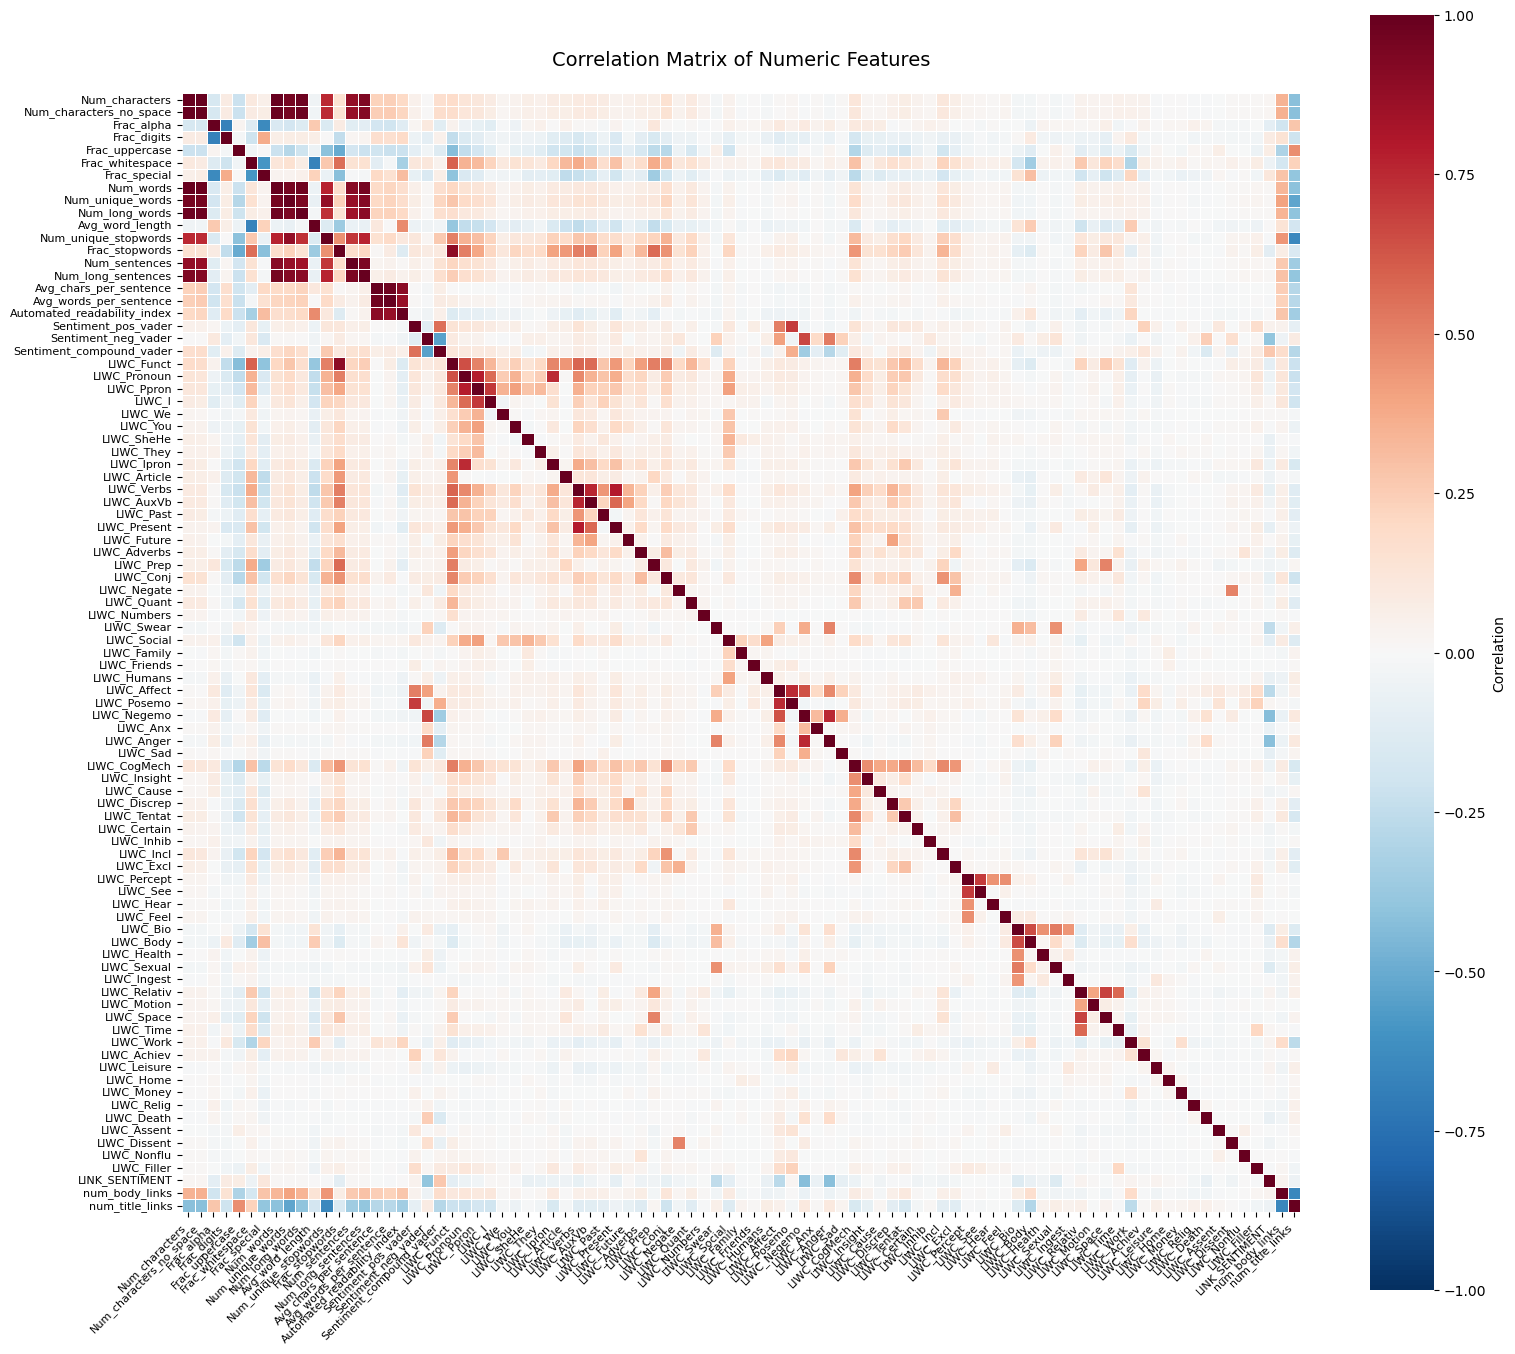

Highly correlated pairs:
[('Num_characters', 'Num_characters_no_space', np.float64(0.9985541824330106)), ('Num_characters', 'Num_words', np.float64(0.9931522540669225)), ('Num_characters', 'Num_unique_words', np.float64(0.957857958855919)), ('Num_characters', 'Num_long_words', np.float64(0.9824284987734778)), ('Num_characters', 'Num_long_sentences', np.float64(0.9306754675195107)), ('Num_characters_no_space', 'Num_words', np.float64(0.9883083871675344)), ('Num_characters_no_space', 'Num_unique_words', np.float64(0.9537009706180258)), ('Num_characters_no_space', 'Num_long_words', np.float64(0.9841135222252332)), ('Num_characters_no_space', 'Num_long_sentences', np.float64(0.9181376128426274)), ('Num_words', 'Num_unique_words', np.float64(0.9608126179212232)), ('Num_words', 'Num_long_words', np.float64(0.9690215133740526)), ('Num_words', 'Num_sentences', np.float64(0.9064252940243297)), ('Num_words', 'Num_long_sentences', np.float64(0.9542071305663617)), ('Num_unique_words', 'Num_long_wo

In [34]:
from src.analysis.virality_analysis.logistic_regression import plot_correlation_matrix, NUMERIC_FEATURES_LIST

highly_correlated_pairs = plot_correlation_matrix(df, NUMERIC_FEATURES_LIST, output_file=None, show=True, correlation_threshold=0.90)

print("Highly correlated pairs:")
print(highly_correlated_pairs)

In [ ]:
fields_to_remove = ['Num_characters', 'Num_sentences', 'Num_characters_no_space', 'Num_unique_words', 'Num_long_words', 'Num_long_sentences', 'Avg_chars_per_sentence', 'Automated_readability_index', 'Num_unique_stopwords']
numeric_features_filtered = NUMERIC_FEATURES_LIST.copy()

for field in fields_to_remove:
    numeric_features_filtered.remove(field)

In [43]:
from src.analysis.virality_analysis.logistic_regression import logistic_regression, save_to_csv
import pandas as pd
import numpy as np

save = True
model, df_model_scaled = logistic_regression(df, features_list=numeric_features_filtered)

predictions = model.predict(df_model_scaled)
predicted_viral = (predictions >= 0.5).astype(int)
actual_viral = df_model_scaled['is_viral_numeric'].values


coef_df = pd.DataFrame({
    'Feature': model.params.index,
    'Coefficient': model.params.values,
    'P-value': model.pvalues.values,
    'Abs_Coefficient': np.abs(model.params.values)
}).sort_values('Abs_Coefficient', ascending=False)

coef_df = coef_df[coef_df['P-value'] < 0.05]

print("\nFEATURE COEFFICIENTS (p-value < 0.05)")
print(coef_df.to_string(index=False))

if save:
    save_to_csv(coef_df)

Viral posts: 13684 (2.00%)
Non-viral posts: 670357 (98.00%)

Formula: is_viral_numeric ~ Frac_alpha + Frac_digits + Frac_uppercase + Frac_whitespace + Frac_special + Num_words + Avg_word_length + Frac_stopwords + Avg_words_per_sentence + Sentiment_pos_vader + Sentiment_neg_vader + Sentiment_compound_vader + LIWC_Funct + LIWC_Pronoun + LIWC_Ppron + LIWC_I + LIWC_We + LIWC_You + LIWC_SheHe + LIWC_They + LIWC_Ipron + LIWC_Article + LIWC_Verbs + LIWC_AuxVb + LIWC_Past + LIWC_Present + LIWC_Future + LIWC_Adverbs + LIWC_Prep + LIWC_Conj + LIWC_Negate + LIWC_Quant + LIWC_Numbers + LIWC_Swear + LIWC_Social + LIWC_Family + LIWC_Friends + LIWC_Humans + LIWC_Affect + LIWC_Posemo + LIWC_Negemo + LIWC_Anx + LIWC_Anger + LIWC_Sad + LIWC_CogMech + LIWC_Insight + LIWC_Cause + LIWC_Discrep + LIWC_Tentat + LIWC_Certain + LIWC_Inhib + LIWC_Incl + LIWC_Excl + LIWC_Percept + LIWC_See + LIWC_Hear + LIWC_Feel + LIWC_Bio + LIWC_Body + LIWC_Health + LIWC_Sexual + LIWC_Ingest + LIWC_Relativ + LIWC_Motion + LIWC

TOP 5 POSTS BY VIRALITY RSS
                                                    title  \
51889                    Reddit! Lets make a Millionaire!   
163587  Moderators of /r/News locking any post having ...   
199539  Reddit CEO caught actively editing comments  t...   
177401  Aaand were back. /r/Apocalympics2016 rises fro...   
179556  Its time. Lets make a millionaire. [Drawing Th...   

                                                 selftext  virality_rss  
51889   ###THE WINNER IS /u/grendelwasamommasboy! Cong...    202.646563  
163587  https://www.reddit.com/r/news/comments/4nqa0t/...    173.179989  
199539  http://archive.is/TErOc -comments before being...     85.392122  
177401  *TLDR: /r/Apocalympics2016 is really good at s...     71.955635  
179556  ###[twitter](https://twitter.com/reddit_millio...     59.279355  


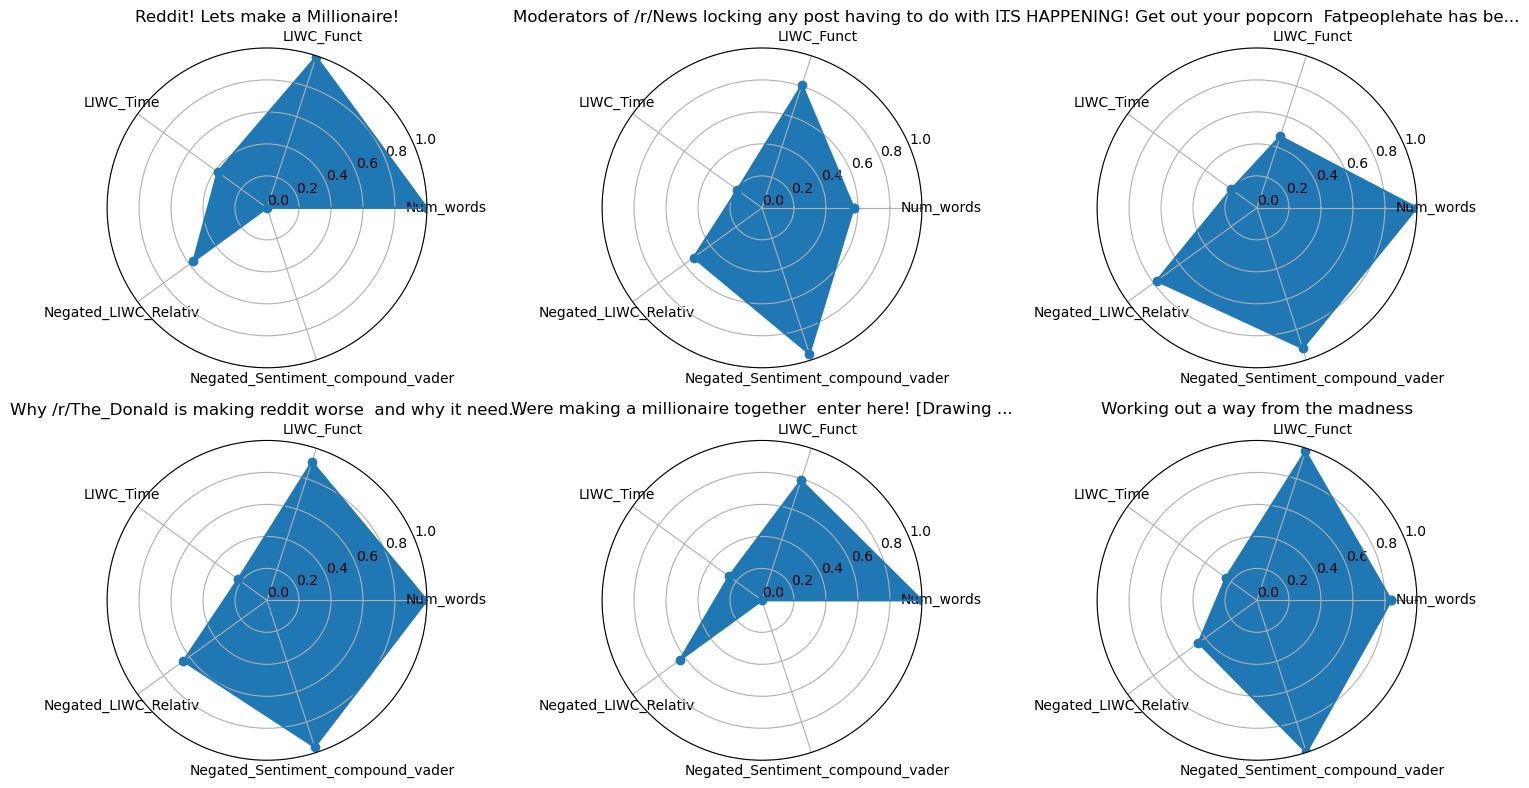

In [44]:
import importlib
import src.analysis.virality_analysis.viral_posts
importlib.reload(src.analysis.virality_analysis.viral_posts)
from src.analysis.virality_analysis.viral_posts import save_coefficients_to_csv, plot_spider_charts


df_sorted = df.sort_values(by='virality_rss', ascending=False)
df_sorted = df_sorted[(df_sorted['selftext'] != '[deleted]') & (df_sorted['selftext'] != '[removed]') & (~df_sorted['selftext'].isna())]
df_sorted = df_sorted[df_sorted['selftext'].str.len() > 50]

print("TOP 5 POSTS BY VIRALITY RSS")
print(df_sorted.head(5)[['title', 'selftext', 'virality_rss']])

columns_to_save = ['Num_words', 'LIWC_Funct', 'LIWC_Time']
negated_columns_to_save = ['LIWC_Relativ', 'Sentiment_compound_vader']
indices_to_save=[0,1,3,16,17,26]

coef_subset = df.iloc[indices_to_save][['title', 'virality_rss'] + columns_to_save + negated_columns_to_save].copy()

for col in coef_subset.columns:
    if col != 'title' and col != 'virality_rss':
        col_min = df[col].quantile(0.05)
        col_max = df[col].quantile(0.95)
        
        if col_max == col_min:
            print(f"Column {col} has no variation in full dataset")
            continue

        coef_subset[col] = (coef_subset[col] - col_min) / (col_max - col_min)
        coef_subset[col] = coef_subset[col].clip(0, 1)

for col in negated_columns_to_save:
    coef_subset[col] = 1 - coef_subset[col]
    coef_subset.rename(columns={col: f'Negated_{col}'}, inplace=True)

save_coefficients_to_csv(coef_subset)

plot_spider_charts(coef_subset)

In [43]:
from src.utils.data_utils import load_final_df
from src.analysis.virality_analysis.get_viral_posts import get_viral_posts

df = load_final_df(calculate_rss=True)
df = get_viral_posts(df, virality_percentile=0.98, window_size='60D')

In [44]:
from importlib import reload
import src.analysis.textual_analysis.textual_analysis as textual_analysis
reload(textual_analysis)
from src.analysis.textual_analysis.textual_analysis import preporcess_text, get_viral_words, save_to_csv
import pandas as pd
import os

OUTPUT_DIR = os.path.join("figures", "text_analysis")

df_text = preporcess_text(df)
print(f"Total posts: {len(df_text)}")

os.makedirs(OUTPUT_DIR, exist_ok=True)

superclusters = df_text['source_supercluster'].unique()
print(f"Found {len(superclusters)} unique source superclusters")

for cluster in superclusters:
    print(f"\nCLUSTER: {cluster}")

    cluster_df = df_text[df_text['source_supercluster'] == cluster].copy()
    cluster_dir = os.path.join(OUTPUT_DIR, str(cluster))
    os.makedirs(cluster_dir, exist_ok=True)
    
    viral_words_cluster = get_viral_words(
        cluster_df, 
        n_top_words=8, 
        alpha=0.001, 
        use_simple_preprocessing=True, 
        text_column='title',
    )
    
    positive_words = viral_words_cluster['positive']
    negative_words = viral_words_cluster['negative']
    
    save_to_csv(positive_words, negative_words, cluster_dir)

    print(f"\nTop {len(positive_words)} positive words ({cluster}):")
    print(positive_words[['word', 'coefficient']].to_string(index=False))
    
    print(f"\nTop {len(negative_words)} negative words ({cluster}):")
    print(negative_words[['word', 'coefficient']].to_string(index=False))

Total posts: 180406
Found 7 unique source superclusters

CLUSTER: Reddit Meta & Community
Processing 56574 posts with valid text and upvote data...
Preprocessing title with simple method (split by spaces, remove punctuation)...


Processing texts (simple): 100%|██████████| 56574/56574 [00:00<00:00, 219918.31it/s]


After preprocessing: 56482 valid posts
Creating TF-IDF features...
Created 10330 features from 56482 posts
Finding optimal lambda (alpha) using 5-fold cross-validation...


Testing alpha values: 100%|██████████| 20/20 [00:18<00:00,  1.08it/s]


Optimal alpha: 0.000100 (5-fold CV R^2: 0.08740798418204132)
Fitting final Lasso regression with alpha=0.000100...

Model R^2 score: 0.09672800794949044
Number of non-zero coefficients: 129

Top 8 positive words (Reddit Meta & Community):
       word  coefficient
millionaire     2.950533
   promises     1.132874
 rthedonald     1.009230
        kia     0.680826
    drawing     0.611724
        pao     0.406258
    welcome     0.368663
     effort     0.354375

Top 8 negative words (Reddit Meta & Community):
     word  coefficient
     eli5    -0.306402
       wp    -0.299963
crosspost    -0.286839
     help    -0.223776
       ip    -0.211144
    whats    -0.207730
  looking    -0.191227
    xpost    -0.185672

CLUSTER: Politics & Society
Processing 24021 posts with valid text and upvote data...
Preprocessing title with simple method (split by spaces, remove punctuation)...


...

Optimal alpha: 0.000100 (5-fold CV R^2: 0.09930946446537661)
Fitting final Lasso regression with alpha=0.000100...

Model R^2 score: 0.14652376087134322
Number of non-zero coefficients: 130

Top 8 positive words (Lifestyle & Niche Interests):
      word  coefficient
      void     0.877209
   weighin     0.736088
 dreamhack     0.671333
conspiracy     0.582156
      clan     0.570747
     nests     0.397927
       war     0.387566
    useful     0.379517

Top 8 negative words (Lifestyle & Niche Interests):
     word  coefficient
  checkin    -0.211275
    xpost    -0.116595
     help    -0.115896
    legal    -0.113144
   advice    -0.104663
 question    -0.104601
questions    -0.081209
   canada    -0.064520

CLUSTER: Sports & Athletics
Processing 11285 posts with valid text and upvote data...
Preprocessing title with simple method (split by spaces, remove punctuation)...


Processing texts (simple): 100%|██████████| 11285/11285 [00:00<00:00, 136719.95it/s]


After preprocessing: 11280 valid posts
Creating TF-IDF features...
Created 2228 features from 11280 posts
Finding optimal lambda (alpha) using 5-fold cross-validation...


Testing alpha values: 100%|██████████| 20/20 [00:00<00:00, 27.67it/s]

Optimal alpha: 0.000100 (5-fold CV R^2: 0.05720017649872853)
Fitting final Lasso regression with alpha=0.000100...

Model R^2 score: 0.08542770773935415
Number of non-zero coefficients: 89

Top 8 positive words (Sports & Athletics):
   word  coefficient
germany     0.277817
   evil     0.188388
    bay     0.175018
sultans     0.125029
    sim     0.123071
   gifs     0.115863
   belt     0.112117
     ea     0.109883

Top 8 negative words (Sports & Athletics):
     word  coefficient
    daily    -0.100748
    xpost    -0.086371
     mock    -0.086242
fenerbahe    -0.068789
     cast    -0.062111
     rnba    -0.053983
    topic    -0.052265
   league    -0.048318


In [47]:
from src.analysis.virality_graph.virality_graph import create_virality_graph, load_final_graph

G = load_final_graph()
print(f"Original graph - Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

virality_G = create_virality_graph(G, aggregation='geometric')
print(f"Virality graph - Nodes: {virality_G.number_of_nodes()}, Edges: {virality_G.number_of_edges()}")

Original graph - Nodes: 28978, Edges: 686012
Virality graph - Nodes: 28351, Edges: 227552


In [ ]:
import src.analysis.virality_graph.virality_graph
from src.analysis.virality_graph.virality_graph import plot_page_centrality
import networkx as nx
from importlib import reload
reload(src.analysis.virality_graph.virality_graph)


pagerank = nx.pagerank(virality_G, weight='weight')

sorted_pagerank = sorted(pagerank.items(), key=lambda x: x[1], reverse=True)
top_10 = sorted_pagerank[:10]

print("\nTop 10 subreddits by PageRank score:")
print("-" * 50)
for i, (subreddit, score) in enumerate(top_10, 1):
    print(f"{i:2d}. {subreddit:30s} {score:.6f}")
print("-" * 50)


Top 10 subreddits by PageRank score:
--------------------------------------------------
 1. iama                           0.014663
 2. askreddit                      0.009450
 3. eatcheapandhealthy             0.008874
 4. pics                           0.008769
 5. videos                         0.006245
 6. todayilearned                  0.006190
 7. outoftheloop                   0.006053
 8. subredditoftheday              0.005735
 9. funny                          0.005701
10. baking                         0.005297
--------------------------------------------------



Subgraph: 20 nodes, 143 edges


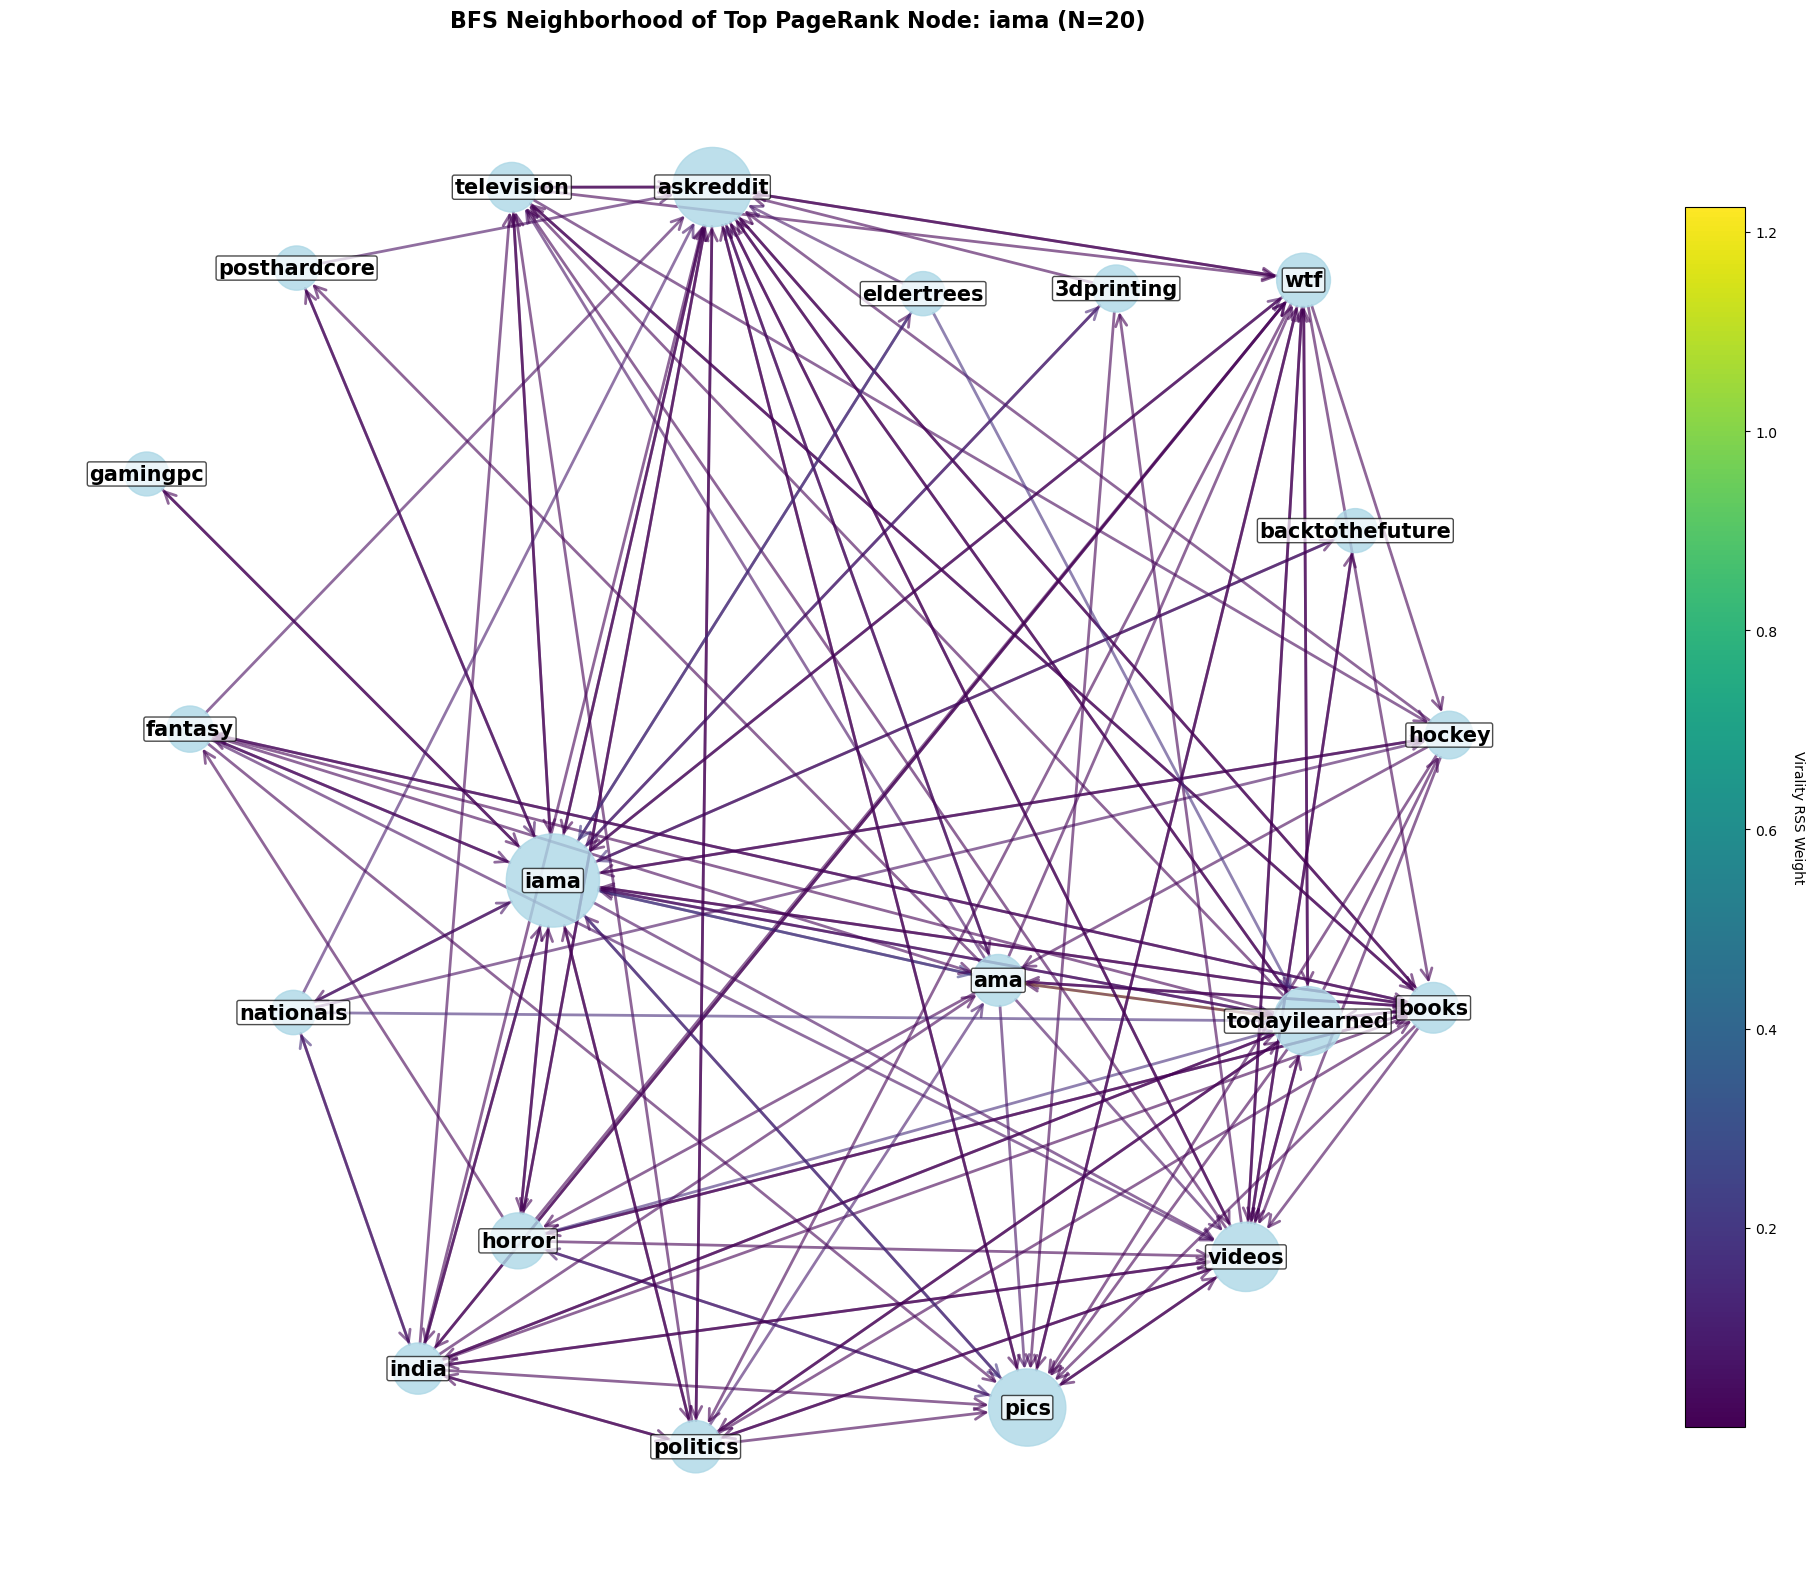

In [49]:
plot_page_centrality(virality_G, pagerank, show=True, export_csv=True)

# Propensity Score Matching

We do propensity score matching for the 10 variables that we expected to have the strongest effect on virality. This information can be used to infer what properties a post should have to increase its virality.
<br>
<br>
 "Due to runtime constraints, the below cell reads the results from src\\analysis\\propensity_analysis\\multi_treatment_psm.ipynb. For each variable we test many different definitions of the treatment for this PSM analysis to determine which treatment/control split yields the maximum average treatment effect on the treated (ATT). The plots are always for the control/treatment split definition which maximizes the ATT for that variables (of the quantile splits tested). We also plot the quantile treatment effect on the top quantile, out of curiosity, to see how each feature effects the most viral posts. We also plotted the ATT across different split definitions to visualize how much the definitions affected the ATT."

Loaded 60 rows from ./data\multi_treatment_psm_summary.pkl.gz
Columns: ['treatment_var', 'threshold_label', 'n_treated', 'n_control', 'n_matched', 'att', 'att_top1pct', 'balance_smd_before', 'balance_smd_after']


d:\Storage\GitHub2\ada-2025-project-standard-deviants-ada\src\analysis\propensity_analysis\visualization_utils.py:121: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


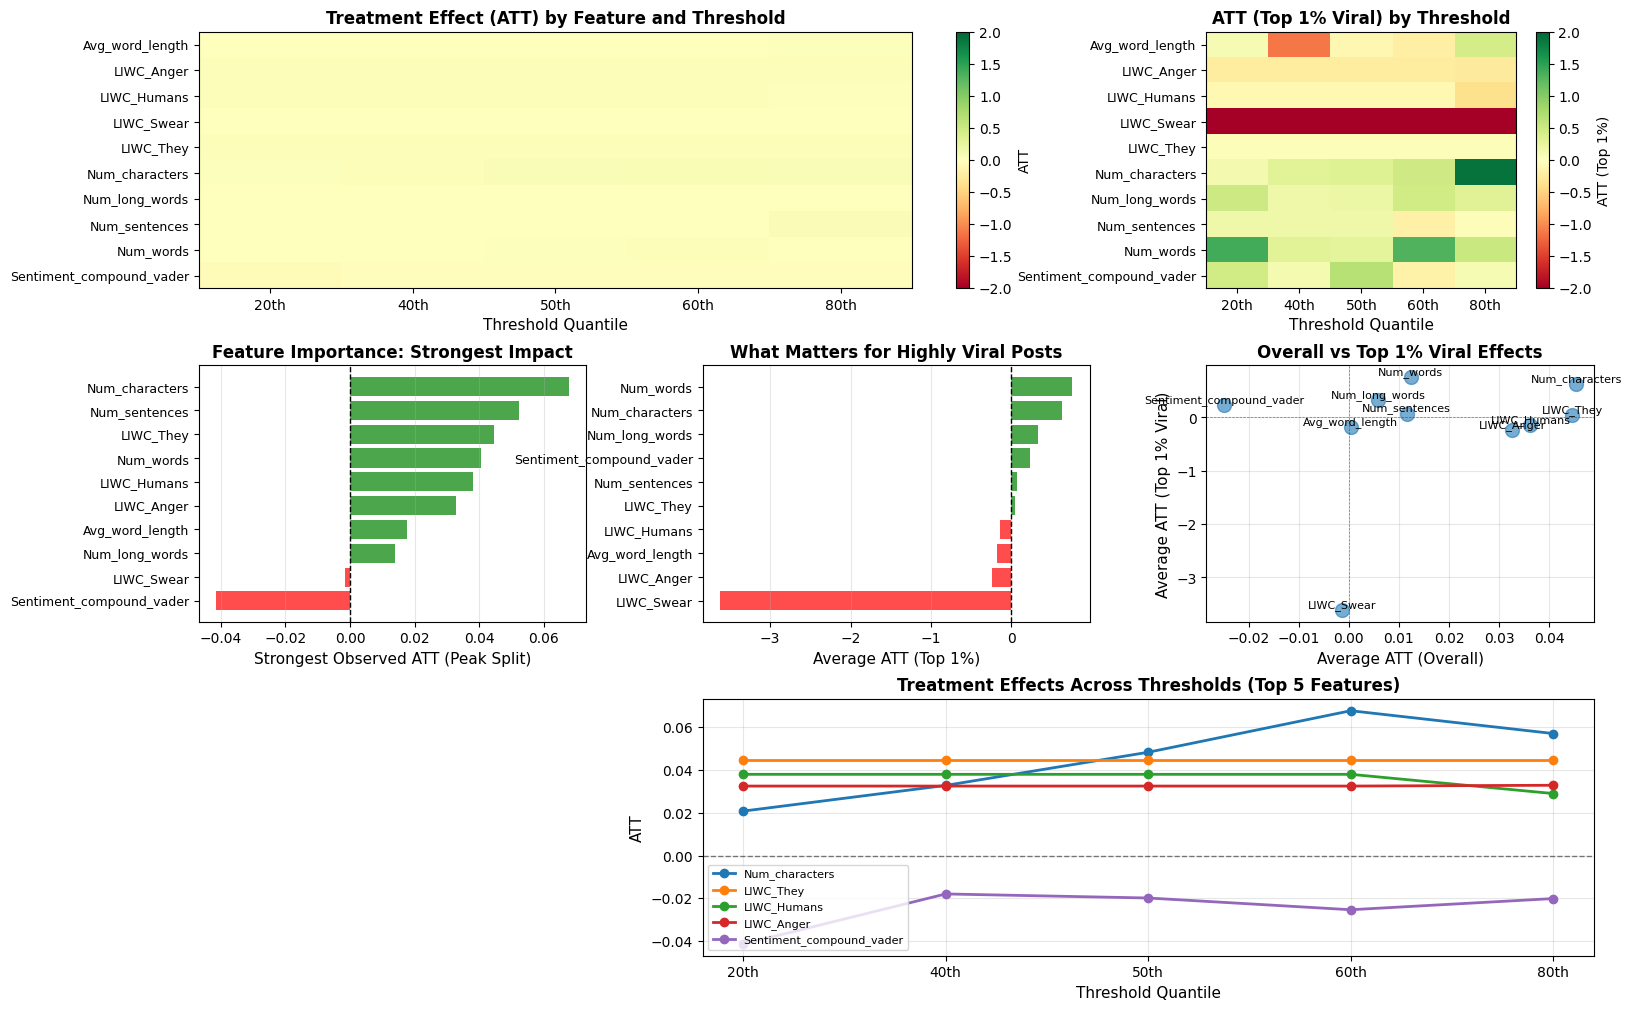


Treatment Effects Across All Variables and Thresholds
Treatment Variable        Threshold    N Treated    N Control    N Matched    Match Rate (%)  ATT          ATT (Top 1%)    SMD before   SMD after   
--------------------------------------------------------------------------------------------------------------------------------------------
Avg_word_length           Median       108,054      48,280       108,054      100.0           -0.0062      -0.1019         1.3542       0.0000      
Avg_word_length           20th         160,471      26,710       160,471      100.0           -0.0033      0.0925          1.5443       0.0000      
Avg_word_length           40th         134,428      45,804       134,428      100.0           -0.0077      -1.1377         1.4711       -0.0000     
Avg_word_length           50th         108,054      48,280       108,054      100.0           -0.0062      -0.1019         1.3542       0.0000      
Avg_word_length           60th         80,120       51,906 

In [ ]:
import os
import gzip
import pandas as pd
from src.analysis.propensity_analysis.visualization_utils import plot_treatment_effects, print_summary_table

SAVE_DIR = "./data"
SUMMARY_GZ_NAME = "multi_treatment_psm_summary.pkl.gz"
gz_path = os.path.join(SAVE_DIR, SUMMARY_GZ_NAME)

if not os.path.exists(gz_path):
    raise FileNotFoundError(f"Could not find: {gz_path}")

with gzip.open(gz_path, "rb") as f:
    df = pd.read_pickle(f)

print(f"Loaded {len(df):,} rows")
print(f"Columns: {len(df.columns)}")

need = {
    "treatment_var", "threshold_label",
    "n_treated", "n_control", "n_matched",
    "att", "att_top1pct",
    "balance_smd_before", "balance_smd_after",
}
missing = need - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns in cache: {missing}")

df = df.copy()
df["treatment_var_str"] = df["treatment_var"].astype(str)
df["threshold_label_str"] = df["threshold_label"].astype(str)

order_map = {"Median": 0, "20th": 1, "40th": 2, "50th": 3, "60th": 4, "80th": 5}
df["threshold_order"] = (
    df["threshold_label_str"].map(order_map).astype("float").fillna(99).astype(int)
)

quantile_df = df[df["threshold_label_str"] != "Median"].copy()

plot_treatment_effects(df)
print_summary_table(df)


Exported strongest impact data to: ./data/plots_propensity\strongest_impact_data.csv
Rows are ordered by highest to lowest absolute impact.
                    var_name  positive_ATT  negative_ATT
10            Num_characters      0.067790           NaN
53             Num_sentences      0.052268           NaN
31                 LIWC_They      0.044543           NaN
22                 Num_words      0.040612           NaN
55               LIWC_Humans      0.038032           NaN
41                LIWC_Anger      0.032909           NaN
47           Avg_word_length      0.017658           NaN
16            Num_long_words      0.014010           NaN
25                LIWC_Swear           NaN     -0.001430
1   Sentiment_compound_vader           NaN     -0.041382


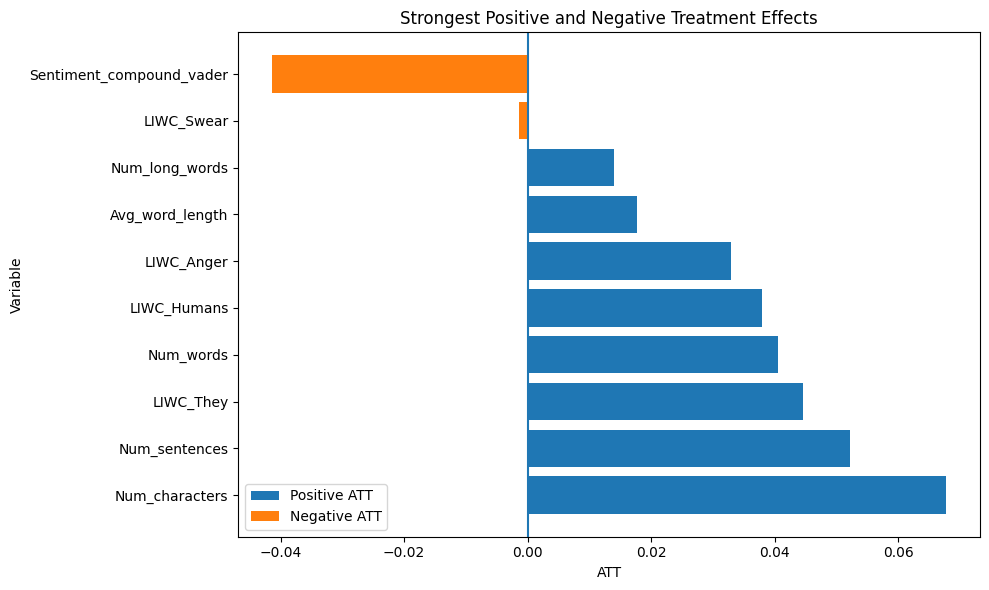

In [22]:
import os
import pandas as pd
import numpy as np

# 1. Define the output directory
output_dir = "./data/plots_propensity"
os.makedirs(output_dir, exist_ok=True)

# 2. Calculate the Strongest Impact (Peak Split) for each variable
idx = quantile_df.groupby("treatment_var_str")["att"].apply(lambda x: np.abs(x).idxmax())
strongest_impact = quantile_df.loc[idx].copy()

# 3. Create absolute value column for sorting and sort Descending
strongest_impact['abs_att'] = strongest_impact['att'].abs()
strongest_impact = strongest_impact.sort_values(by='att', ascending=False)

# 4. Create the positive and negative ATT columns
strongest_impact['positive_ATT'] = strongest_impact['att'].apply(lambda x: x if x > 0 else np.nan)
strongest_impact['negative_ATT'] = strongest_impact['att'].apply(lambda x: x if x < 0 else np.nan)

# 5. Select and rename columns for export
export_df = strongest_impact[['treatment_var_str', 'positive_ATT', 'negative_ATT']].copy()
export_df.rename(columns={'treatment_var_str': 'var_name'}, inplace=True)

# 6. Save to CSV
csv_path = os.path.join(output_dir, "strongest_impact_data.csv")
export_df.to_csv(csv_path, index=False)

print(f"Exported strongest impact data to: {csv_path}")
print("Rows are ordered by highest to lowest absolute impact.")
# Display the top 10 rows to verify sorting
print(export_df.head(10))




import matplotlib.pyplot as plt

# Sort for cleaner plotting (top to bottom)
plot_df = export_df

plt.figure(figsize=(10, max(6, 0.35 * len(plot_df))))

plt.barh(
    plot_df['var_name'],
    plot_df['positive_ATT'],
    label='Positive ATT'
)
plt.barh(
    plot_df['var_name'],
    plot_df['negative_ATT'],
    label='Negative ATT'
)

plt.axvline(0)
plt.xlabel("ATT")
plt.ylabel("Variable")
plt.title("Strongest Positive and Negative Treatment Effects")
plt.legend()
plt.tight_layout()

plt.show()


We see from the above plot that Num_characters has the strongest potential ATT. This means that when the post is longer than the threshold (which we will later see is 135 characters), for a pair of posts which are similar based on the propensity matching with one post less than 135 chars and one more than 135 chars, we can expect that on average the post with more than 135 chars will have a 0.067 increase in virality score. Since this is the most impactful feature, we add special attential to it in the following analysis below.

Saved: ./data/plots_propensity\num_characters_att_by_raw_split.csv


,Quantile,SplitValue_raw,ATT
0,20,57.0,0.020818
1,40,87.0,0.032840
2,50,106.0,0.048360
3,60,135.0,0.067790
4,80,481.0,0.057106


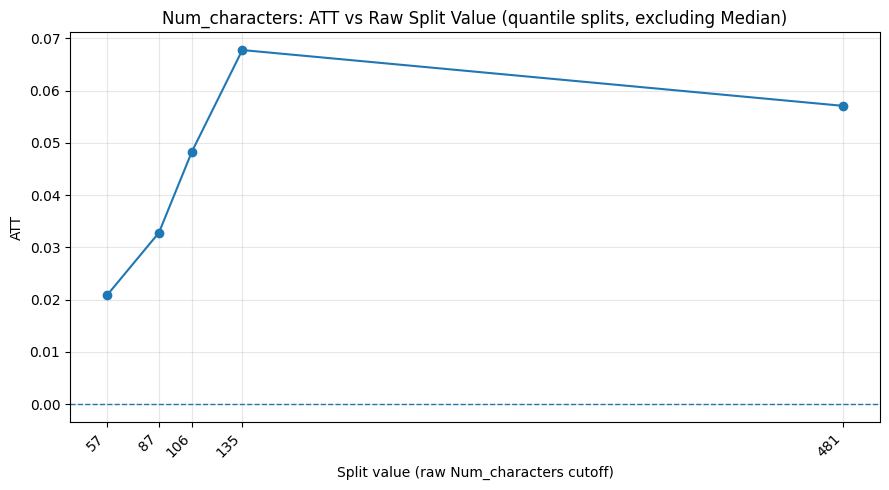

In [10]:
# Recover the RAW split values for each quantile (consistent w/ df_clean standardization)
# then plot ATT with x-axis = raw split value (not quantile) and save the CSV

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.utils.data_utils import load_final_df

OUTCOME_VAR = "virality_rss"
treatment_var = "Num_characters"
out_dir = "./data/plots_propensity"
os.makedirs(out_dir, exist_ok=True)

# Get ATT by quantile from the LOADED cache df (exclude median)
sub = df[(df["treatment_var_str"] == treatment_var) & (df["threshold_label_str"] != "Median")].copy()
if sub.empty:
    raise RuntimeError("No non-median quantile rows found for Num_characters in the loaded cache.")

sub["Quantile"] = sub["threshold_label_str"].astype(str).str.replace("th", "", regex=False)
sub["Quantile"] = pd.to_numeric(sub["Quantile"], errors="coerce")
sub = sub.dropna(subset=["Quantile", "att"]).sort_values("Quantile")

att_df = sub[["Quantile", "att"]].rename(columns={"att": "ATT"}).reset_index(drop=True)

# 2) Reconstruct df_clean’s scaling, compute raw split values for those quantiles
df_analysis = load_final_df()

exclude = [
    'treat', 'ups', 'virality_rss', 'score', 'num_comments', 'total_votes',
    'downs', 'subreddit_subscribers', 'Sentiment_pos_vader', 'Sentiment_neg_vader',
    'Sentiment_compound_vader', 'total_awards_received', 'upvote_ratio', 'gilded',
    'num_crossposts', 'is_video', 'created', 'approved_by', 'mod_reason_title',
    'top_awarded_type', 'report_reasons', 'removed_by', 'num_reports',
    'mod_reason_by', 'treatment_tags', 'view_count', 'banned_at_utc', 'likes',
    'banned_by', 'num_duplicates', 'discussion_type', 'mod_note', 'category',
    'approved_at_utc', 'pwls', 'wls', 'Frac_special', 'LIWC_Pronoun',
    'LIWC_Ppron', 'LIWC_Ipron', 'Frac_alpha', 'Frac_digits', 'Frac_whitespace',
    'is_self', 'created_utc', 'Num_unique_words', 'Num_unique_words_no_space'
]

numeric_cols = df_analysis.select_dtypes(include=[np.number]).columns.tolist()
covariates = [c for c in numeric_cols if c not in exclude]

# Match the exact analysis sample used to compute means/stds in prepare_data
df_sub = df_analysis.dropna(subset=covariates + [OUTCOME_VAR]).copy()

x_raw = df_sub[treatment_var].astype(float).to_numpy()
mu = float(np.mean(x_raw))
sd = float(np.std(x_raw, ddof=1))
if not np.isfinite(sd) or sd <= 0:
    raise RuntimeError(f"Degenerate std for {treatment_var}: sd={sd}")

# Standardized values used in df_clean
x_z = (x_raw - mu) / sd

# Compute z-thresholds and convert to raw thresholds for the quantiles present in att_df
quantiles = att_df["Quantile"].astype(int).tolist()
z_thresh = {q: float(np.percentile(x_z, q)) for q in quantiles}
raw_thresh = {q: float(z_thresh[q] * sd + mu) for q in quantiles}

thresh_df = pd.DataFrame({
    "Quantile": quantiles,
    "SplitValue_raw": [raw_thresh[q] for q in quantiles],
    "SplitValue_zscore": [z_thresh[q] for q in quantiles],
})

# 3) Merge + save CSV + plot with x as the raw split value
out_df = (
    att_df.merge(thresh_df, on="Quantile", how="left")
          .sort_values("SplitValue_raw")
          .reset_index(drop=True)
)

csv_out = os.path.join(out_dir, "num_characters_att_by_raw_split.csv")
out_df[["Quantile", "SplitValue_raw", "ATT"]].to_csv(csv_out, index=False)
print(f"Saved: {csv_out}")
display(out_df[["Quantile", "SplitValue_raw", "ATT"]])

# Line plot
plt.figure(figsize=(9, 5))
plt.plot(out_df["SplitValue_raw"].values, out_df["ATT"].values, marker="o")
plt.axhline(0, linestyle="--", linewidth=1)

# ticks at raw split values
xticks = out_df["SplitValue_raw"].values
plt.xticks(xticks, [f"{x:,.0f}" for x in xticks], rotation=45, ha="right")

plt.xlabel("Split value (raw Num_characters cutoff)")
plt.ylabel("ATT")
plt.title("Num_characters: ATT vs Raw Split Value (quantile splits, excluding Median)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Here we show the ATT results of the num_characters variable over all possible definitions of treatment. We chose to define treatment at 5 quantiles to test and build a separate propensity score matching model for each one. We see that 135 characters seems to be a sweet spot. This likely shows that to maximize chance of virality, the post must be long enough to be 

Loading data...
Preparing data...
Running detailed analysis for Num_characters...
Saved results at: ./data\num_characters_detailed_smd.pkl.gz

Top 10 Covariates by Absolute SMD After Matching:
                      covariate  smd_before  smd_after
1                Frac_uppercase   -1.309837  -0.270481
4                    LIWC_Funct    0.882266  -0.153208
47                    LIWC_Body    0.235568   0.136351
3   Automated_readability_index    0.608133   0.127370
33                 LIWC_CogMech    0.585766  -0.102678
40                    LIWC_Incl    0.455069  -0.095576
18                    LIWC_Conj    0.667279  -0.093543
2                Frac_stopwords    0.785410  -0.086213
17                    LIWC_Prep    0.360009  -0.085955
51                 LIWC_Relativ    0.118616  -0.079851

=== PSM w/ percentile common support + tighter caliper ===
treatment_var: Num_characters
threshold_median: -0.27438755598771614
support_q: 0.01
support_ps_low: 0.04650164993480184
support_ps_high: 0.83

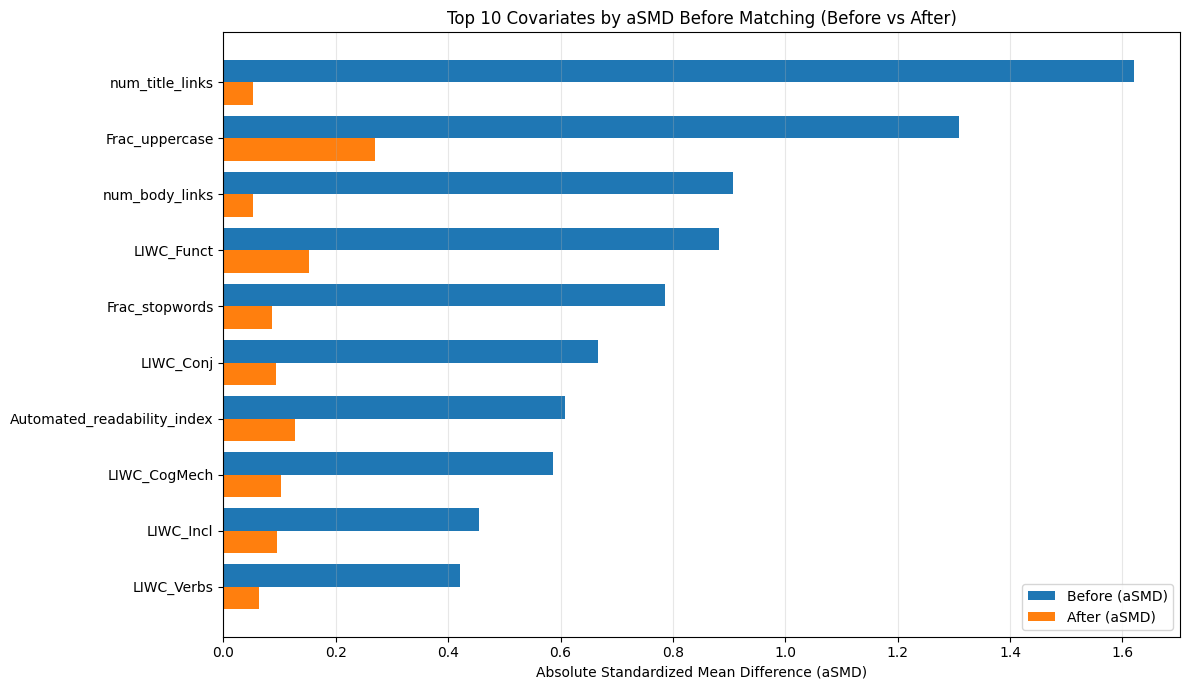

In [ ]:
import os
from src.utils.data_utils import load_final_df
from src.analysis.propensity_analysis.psm_analysis_utils import (
    prepare_analysis_data,
    run_psm_analysis_detailed,
    run_psm_with_percentile_support,
    save_analysis_results,
    print_top_covariates_by_smd,
    print_analysis_summary,
    print_balance_statistics,
    COVARIATE_EXCLUSIONS
)
from src.analysis.propensity_analysis.visualization_utils import (
    export_sorted_covariate_balance,
    plot_covariate_balance
)

TREATMENT_VAR = 'Num_characters'
SAVE_DIR = "./data"
DETAILED_FILE_NAME = "num_characters_detailed_smd.pkl.gz"
OUTPUT_DIR = "./data/plots_propensity"

df_analysis = load_final_df()

df_clean, covariates = prepare_analysis_data(df_analysis)

result = run_psm_analysis_detailed(
    TREATMENT_VAR,
    df_clean,
    covariates,
    exclusions=COVARIATE_EXCLUSIONS.get(TREATMENT_VAR, [])
)

if result is None:
    raise RuntimeError("PSM analysis returned None.")

out_path = save_analysis_results(result, SAVE_DIR, DETAILED_FILE_NAME)
print(f"Saved to {out_path}")

print_top_covariates_by_smd(result['covariate_balance'], n=10, sort_by='smd_after')

result3 = run_psm_with_percentile_support(
    treatment_var=TREATMENT_VAR,
    df=df_clean,
    covariates_list=covariates,
    exclusions=COVARIATE_EXCLUSIONS.get(TREATMENT_VAR, [])
)

print_analysis_summary(result3["summary"])

print_top_covariates_by_smd(result3["covariate_balance"], n=10, sort_by='smd_after')

print_balance_statistics(result3["covariate_balance"])

gz_path = os.path.join(SAVE_DIR, DETAILED_FILE_NAME)
export_sorted_covariate_balance(gz_path, OUTPUT_DIR)

csv_path = os.path.join(OUTPUT_DIR, "num_characters_covariate_balance.csv")
plot_covariate_balance(csv_path, top_n=10)


After we have done our propensity score matching, we want to make sure that it actually worked to give us groups who have similar properites to each other, and that it removed imbalances of the covariates. Here we show blue bars for the standard mean difference of covariates between groups in the propensity score matching model before and after matching. We see that before matching the standard mean difference between the treatment and control group for many variables is quite high, showing the groups are not balanced. After matching they are all near zero, and all around or below the 0.25 threshold, which is typically used in propensity score matching to determine balance among groups.